# Can a machine rediscover Kepler's laws?

Kepler's three laws are recovered here from raw position and velocity data, with no physics assumed beyond the data itself.

- **Data:** daily heliocentric positions (AU) and velocities (AU/day) of the eight planets for 2020-2024, downloaded from the NASA JPL Horizons system with `get_planet_data.ipynb`.
- **Mars** is the main example, as it was for Kepler.
- **Law 1:** the orbit is an ellipse with the Sun at one focus. Checked by fitting 1/r against cos(theta) with linear regression.
- **Law 2:** equal areas in equal times. Checked through the area swept per day and the angular momentum.
- **Law 3:** T^2 is proportional to a^3. Checked across the planets with a log-log regression.
- **Extra:** predicting the orbit with Fourier regression, and retrograde motion seen from Earth.

Run the cells from top to bottom. Plots are saved to `plots/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
sns.set_theme(style="whitegrid")

from IPython.display import display

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import LinearRegression


from sympy import symbols, Matrix

# Utility functions

In [2]:
def get_planet_df(planet, path="../planet_data/"):
    df = pd.read_csv(f"{path}{planet}_orbit.csv")
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
    df.index = pd.DatetimeIndex(df.index, freq='D')

    df['R'] = np.sqrt(df['X']**2 + df['Y']**2 + df['Z']**2)
    df['V'] = np.sqrt(df['VX']**2 + df['VY']**2 + df['VZ']**2)

    return df

def get_perihelion_aphelion(df_):
    t_R_min, t_R_max = df_["R"].idxmin(), df_["R"].idxmax()
    return df_.loc[t_R_min], df_.loc[t_R_max]

def get_time_period(planet):
    try:
        R = planets_df[planet]["R"].values
        idxs = [i for i in range(1, len(R)-1) if (R[i] > R[i-1]) and (R[i] > R[i+1])]
        T_estimates = [idxs[i] - idxs[i-1] for i in range(1, len(idxs))]
        return np.mean(T_estimates)
    except:
        return None

def get_semi_major_axis(planet):
    return (planets_df[planet]["R"].max() + planets_df[planet]["R"].min())/2

def do_regression(X, y):
    reg = LinearRegression()
    reg.fit(X, y)    
    return reg

def get_area_swept(start, n_days=1):
    """Area swept by the radius vector over n_days, starting at day `start`.
    Each day contributes the triangle (Sun, r_i, r_i+1) with area |r_i x r_i+1| / 2."""
    df_ = df[(df["day"] >= start) & (df["day"] <= start + n_days)]
    xyz = df_[["X", "Y", "Z"]].values
    return sum(np.linalg.norm(np.cross(xyz[i], xyz[i+1])) / 2 for i in range(len(xyz) - 1))

def plot_area_swept(start_day, n_days=1, color="red"):
        
    direction_start = df[df["day"] == start_day][["X", "Y"]].values[0]
    direction_stop = df[df["day"] == start_day+n_days][["X", "Y"]].values[0]

    mask = (df["day"] > start_day) & (df["day"] <= start_day+n_days)
    segment = df[mask][["X", "Y"]].values
    region = np.vstack([[0, 0], segment, [0, 0]])
    plt.fill(region[:, 0], region[:, 1], alpha=0.2, color=color, label=f"day: {start_day} - {start_day+n_days}")
    plt.title(f"Area = {get_area_swept(start_day, n_days)} A.U^2")
    
    plt.xlabel("X [A.U]")
    plt.ylabel("Y [A.U]")
    plt.axis("equal")
    
    plt.legend(loc="upper right")

planet_colors = {
    "mercury": "gray",
    "venus":   "orange",
    "earth":   "blue",
    "mars":    "brown",
    "jupiter": "orange",
    "saturn":  "goldenrod",
    "uranus":  "lightblue",
    "neptune": "darkblue"
}

def get_positions_from_earth(planet):
    earth_df = planets_df["earth"]
    return planets_df[planet] - earth_df

# Read the planet data:

In [3]:
planets = ["mercury", "venus", "earth", "mars", "jupiter", "saturn", "uranus", "neptune"]
planets_df = {planet: get_planet_df(planet) for planet in planets}

planet_ = "mars"
df = get_planet_df(planet_)
df.head()

,day,X,Y,Z,VX,VY,VZ,R,V
date,,,,,,,,,
2020-01-01,0,-1.320108,-0.885757,0.013829,0.008321,-0.010423,-0.000423,1.589793,0.013344
2020-01-02,1,-1.311738,-0.896147,0.013406,0.008418,-0.010357,-0.000424,1.588684,0.013353
2020-01-03,2,-1.303272,-0.906471,0.012982,0.008514,-0.010291,-0.000425,1.587569,0.013363
2020-01-04,3,-1.294709,-0.916728,0.012557,0.008611,-0.010223,-0.000425,1.586449,0.013373
2020-01-05,4,-1.286051,-0.926917,0.012131,0.008706,-0.010155,-0.000426,1.585323,0.013383


# EDA

## Plot X, Y, Z over time

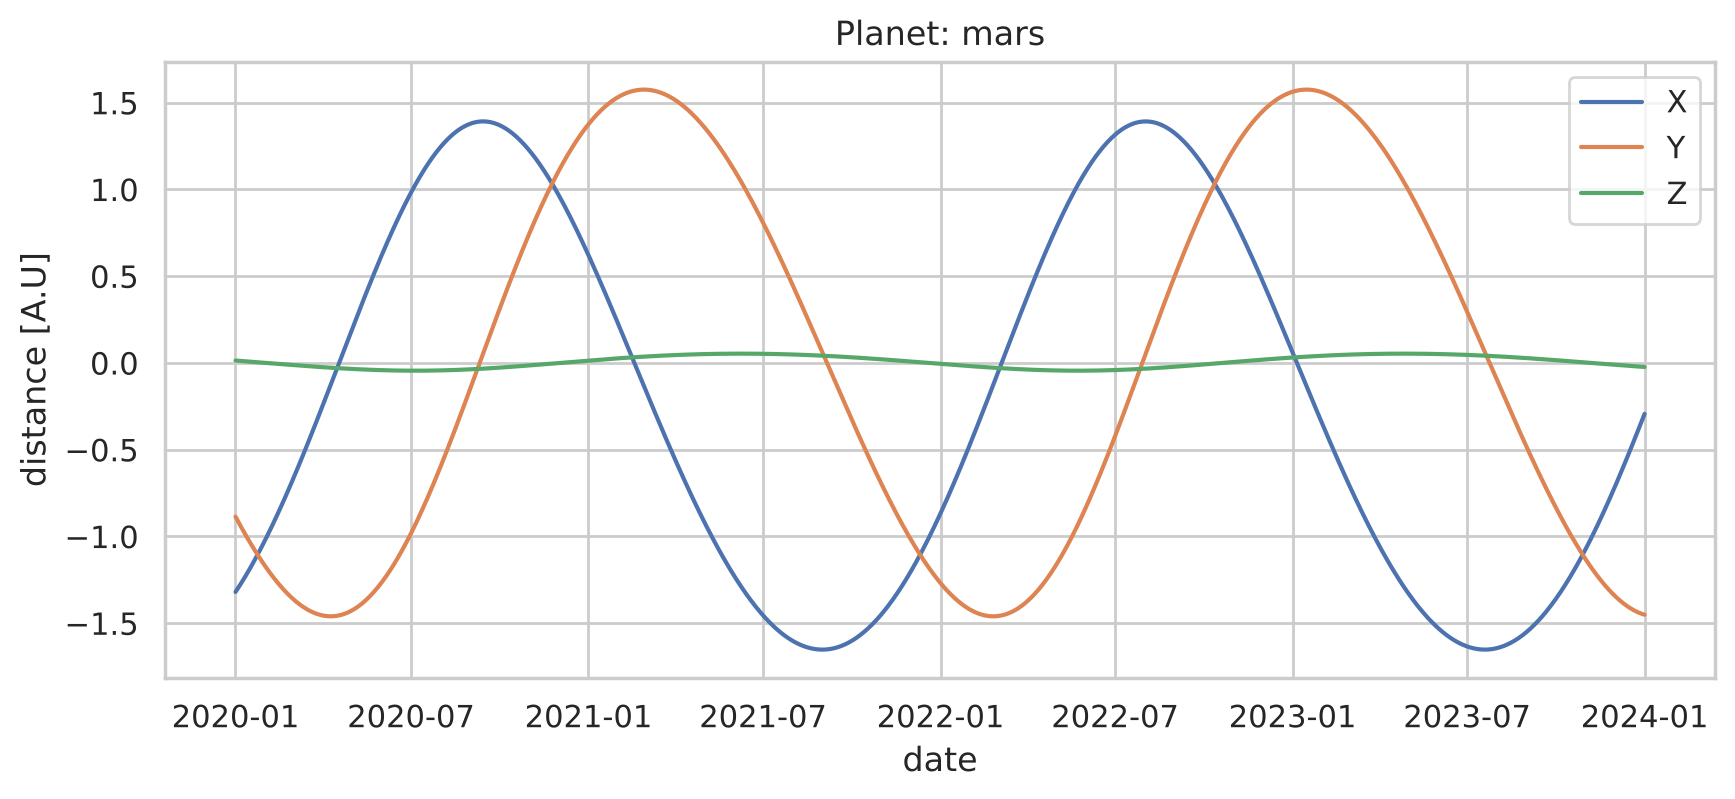

In [4]:
plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x=df.index, y="X", label="X")
sns.lineplot(data=df, x=df.index, y="Y", label="Y")
sns.lineplot(data=df, x=df.index, y="Z", label="Z")
plt.ylabel("distance [A.U]")
plt.legend()
plt.title(f"Planet: {planet_}")
plt.savefig(f"plots/xyz_overtime_{planet_}.png", dpi=150, bbox_inches='tight')

## Plot R over time 

1.5306901234070365 1.3813059321758783 1.66595502674837 0.09769501637123633


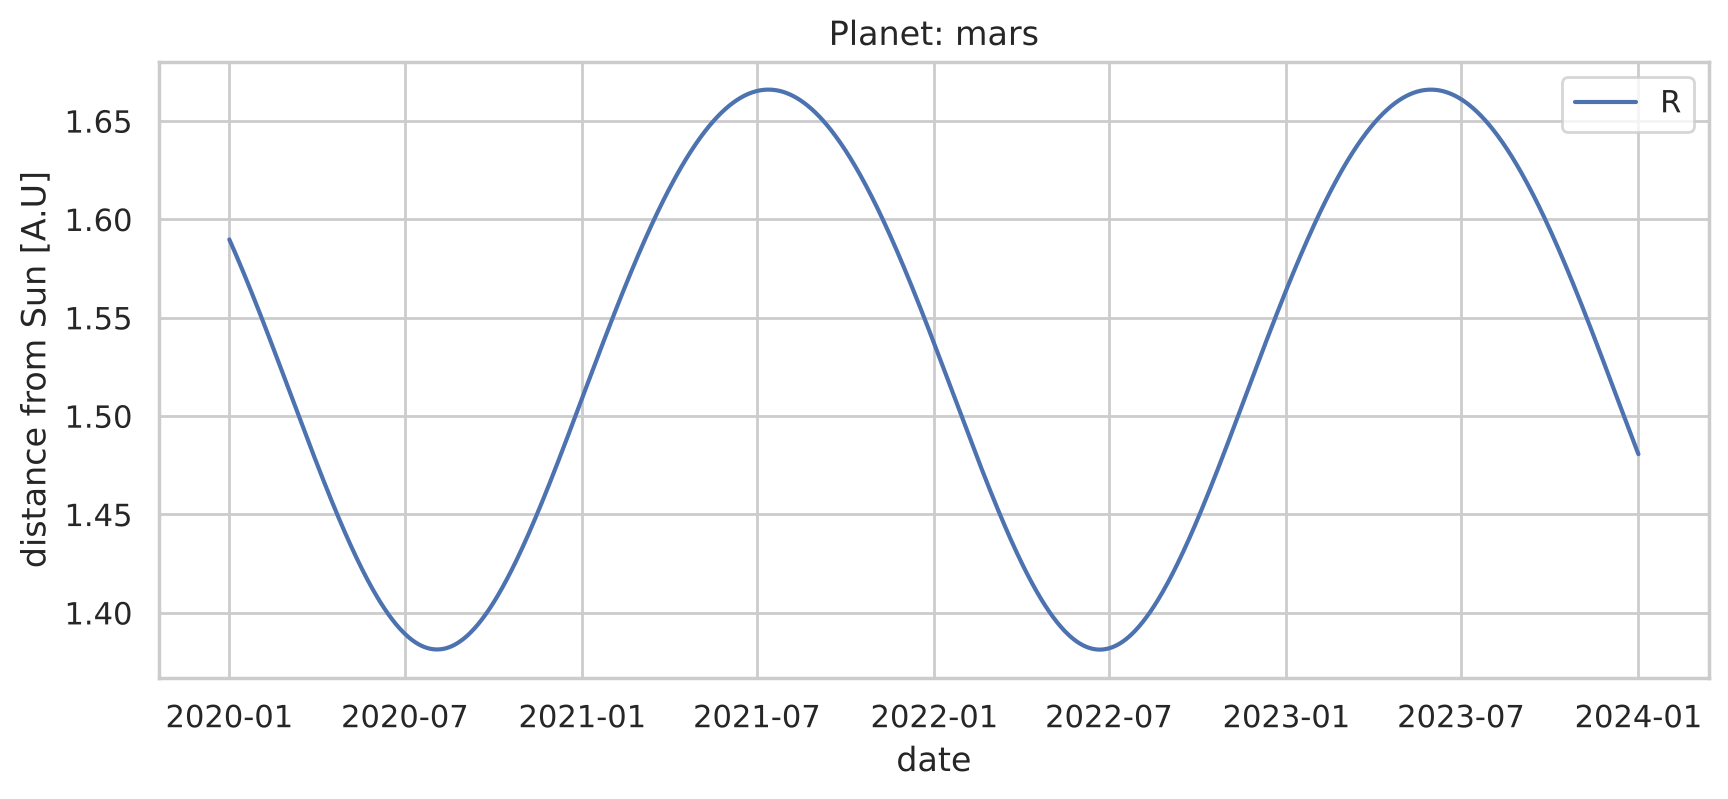

In [5]:
R_mean, R_min, R_max, R_std = df["R"].mean(), df["R"].min(), df["R"].max(), df["R"].std()
print(R_mean, R_min, R_max, R_std)

plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x=df.index, y="R", label="R")
plt.ylabel("distance from Sun [A.U]")

plt.legend()
plt.title(f"Planet: {planet_}")
plt.savefig(f"plots/distance_from_sun_overtime_{planet_}.png", dpi=150, bbox_inches='tight')

## Plot speed vs R 

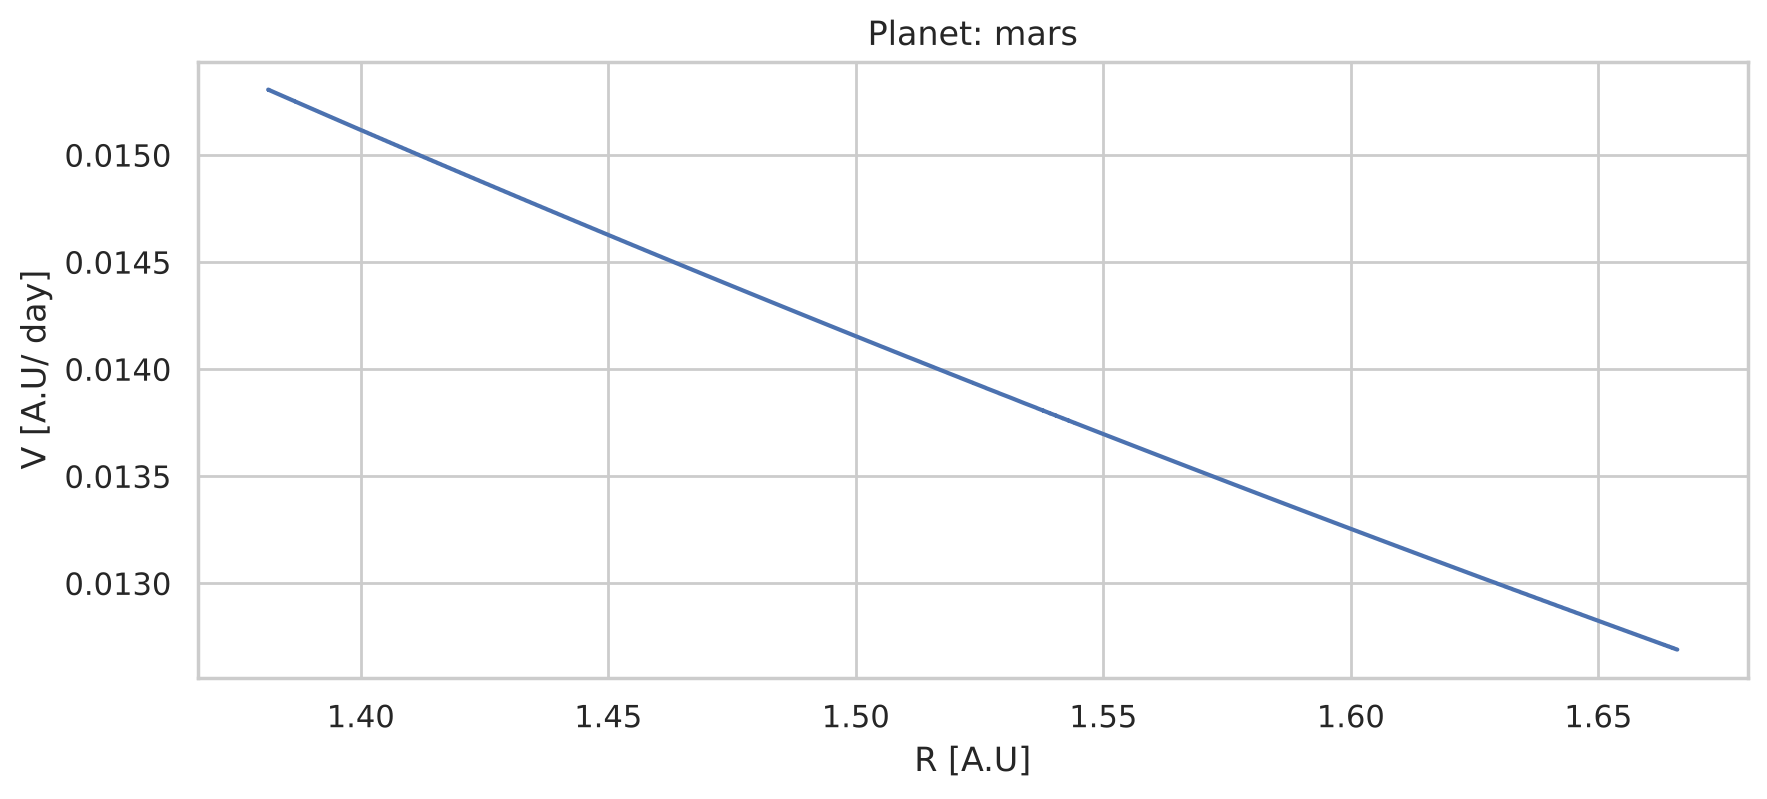

In [6]:
plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x="R", y="V")
plt.xlabel("R [A.U]")
plt.ylabel("V [A.U/ day]")
plt.title(f"Planet: {planet_}")
plt.savefig(f"plots/speed_versus_distance_{planet_}.png", dpi=150, bbox_inches='tight')

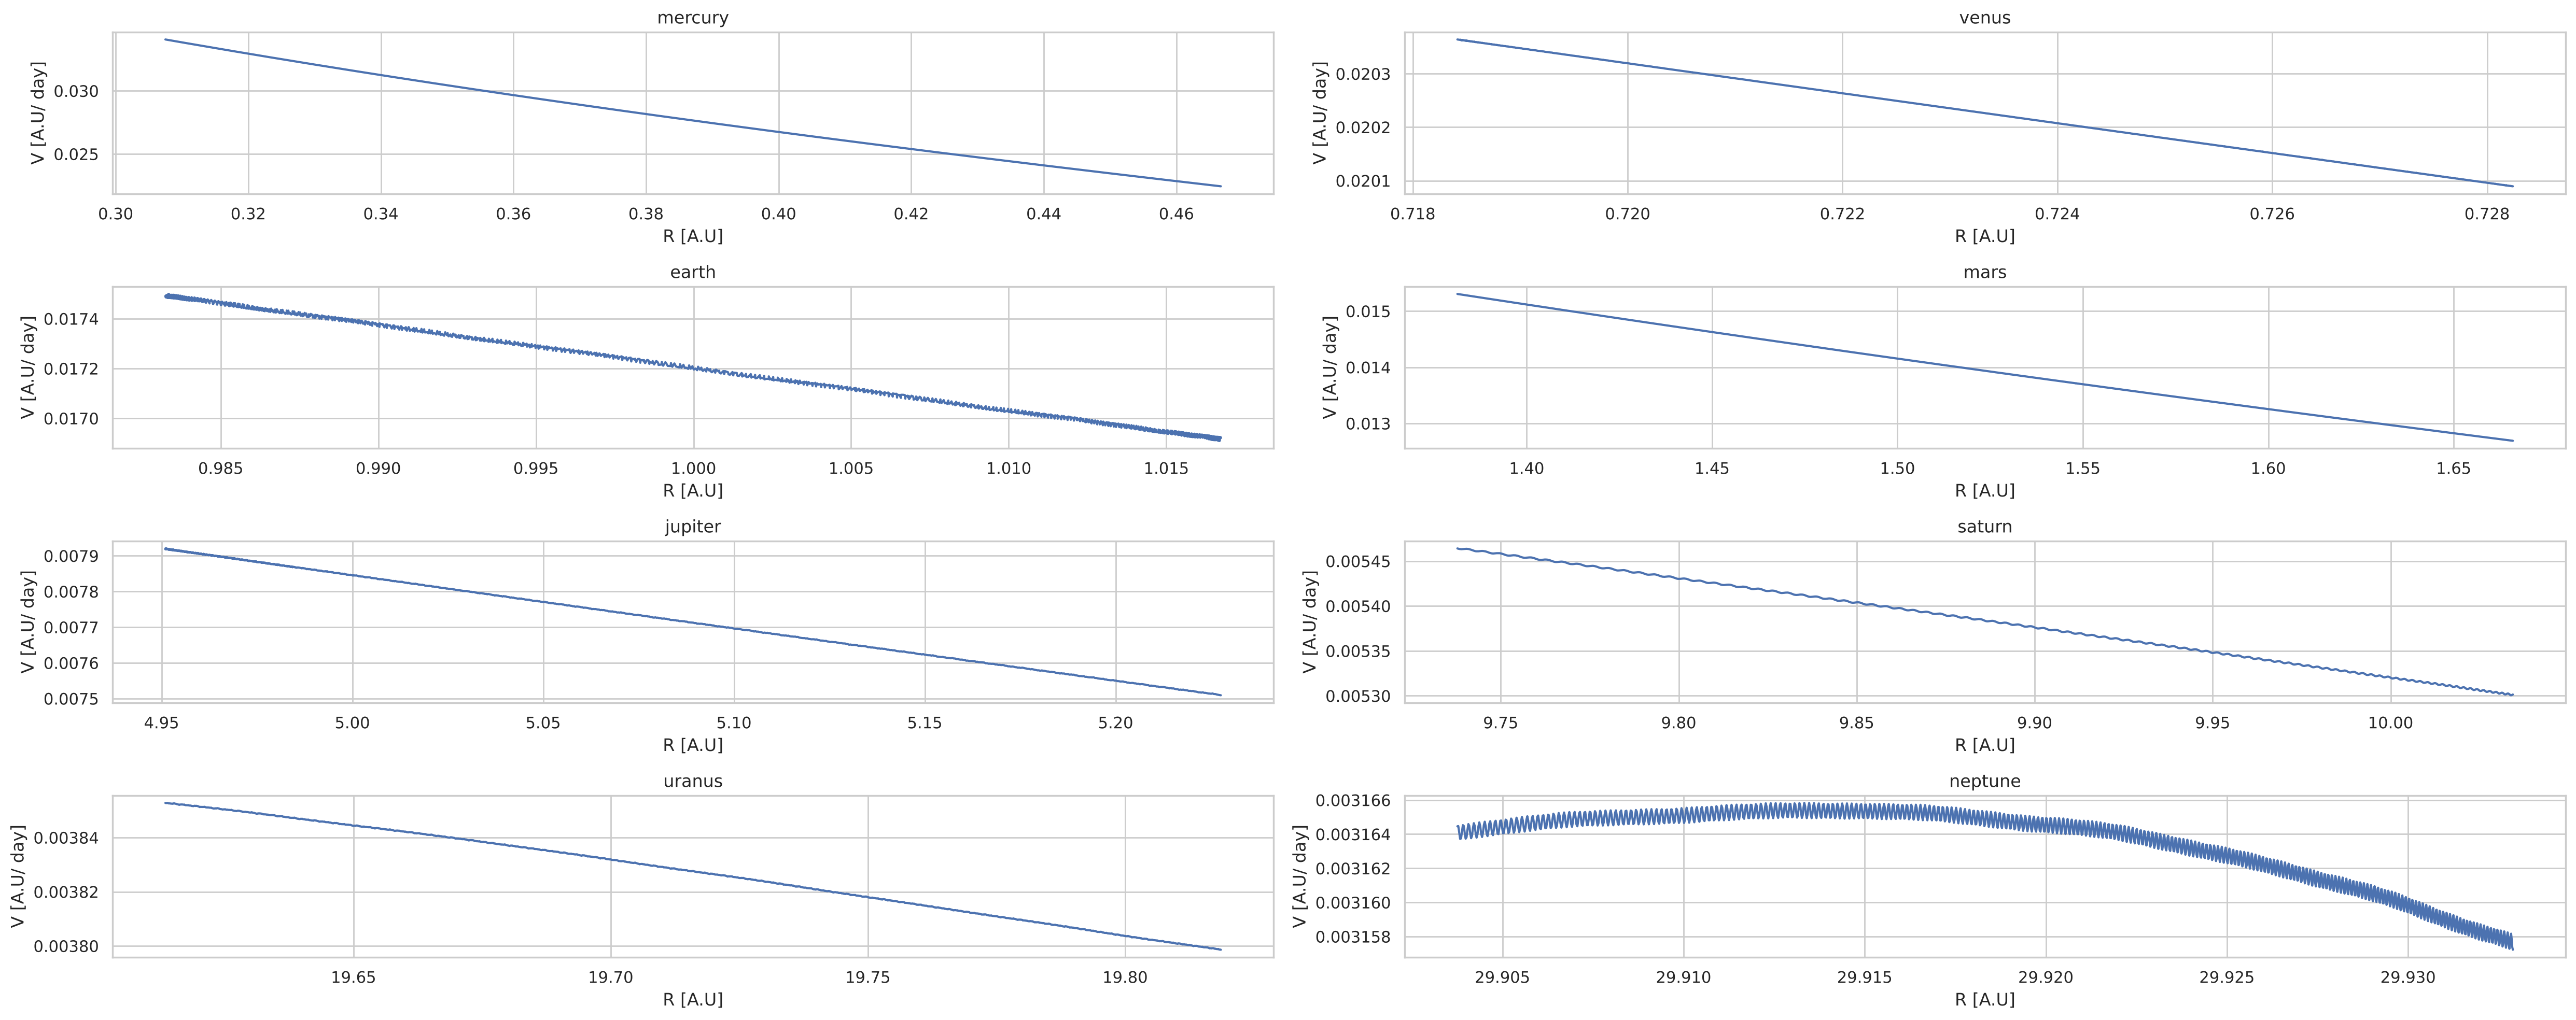

In [7]:
fig, ax = plt.subplots(nrows=4, ncols=2, figsize=(25, 10))
ax = ax.flatten()
for i, planet in enumerate(planets):
    sns.lineplot(data=planets_df[planet][["R", "V"]], x="R", y="V", ax=ax[i])
    ax[i].set_xlabel("R [A.U]")
    ax[i].set_ylabel("V [A.U/ day]")
    ax[i].set_title(planet)
plt.tight_layout()
plt.savefig(f"plots/speed_versus_distance_all_planets.png", dpi=150, bbox_inches='tight')

# Orbit Plot

## Plot X vs Y 

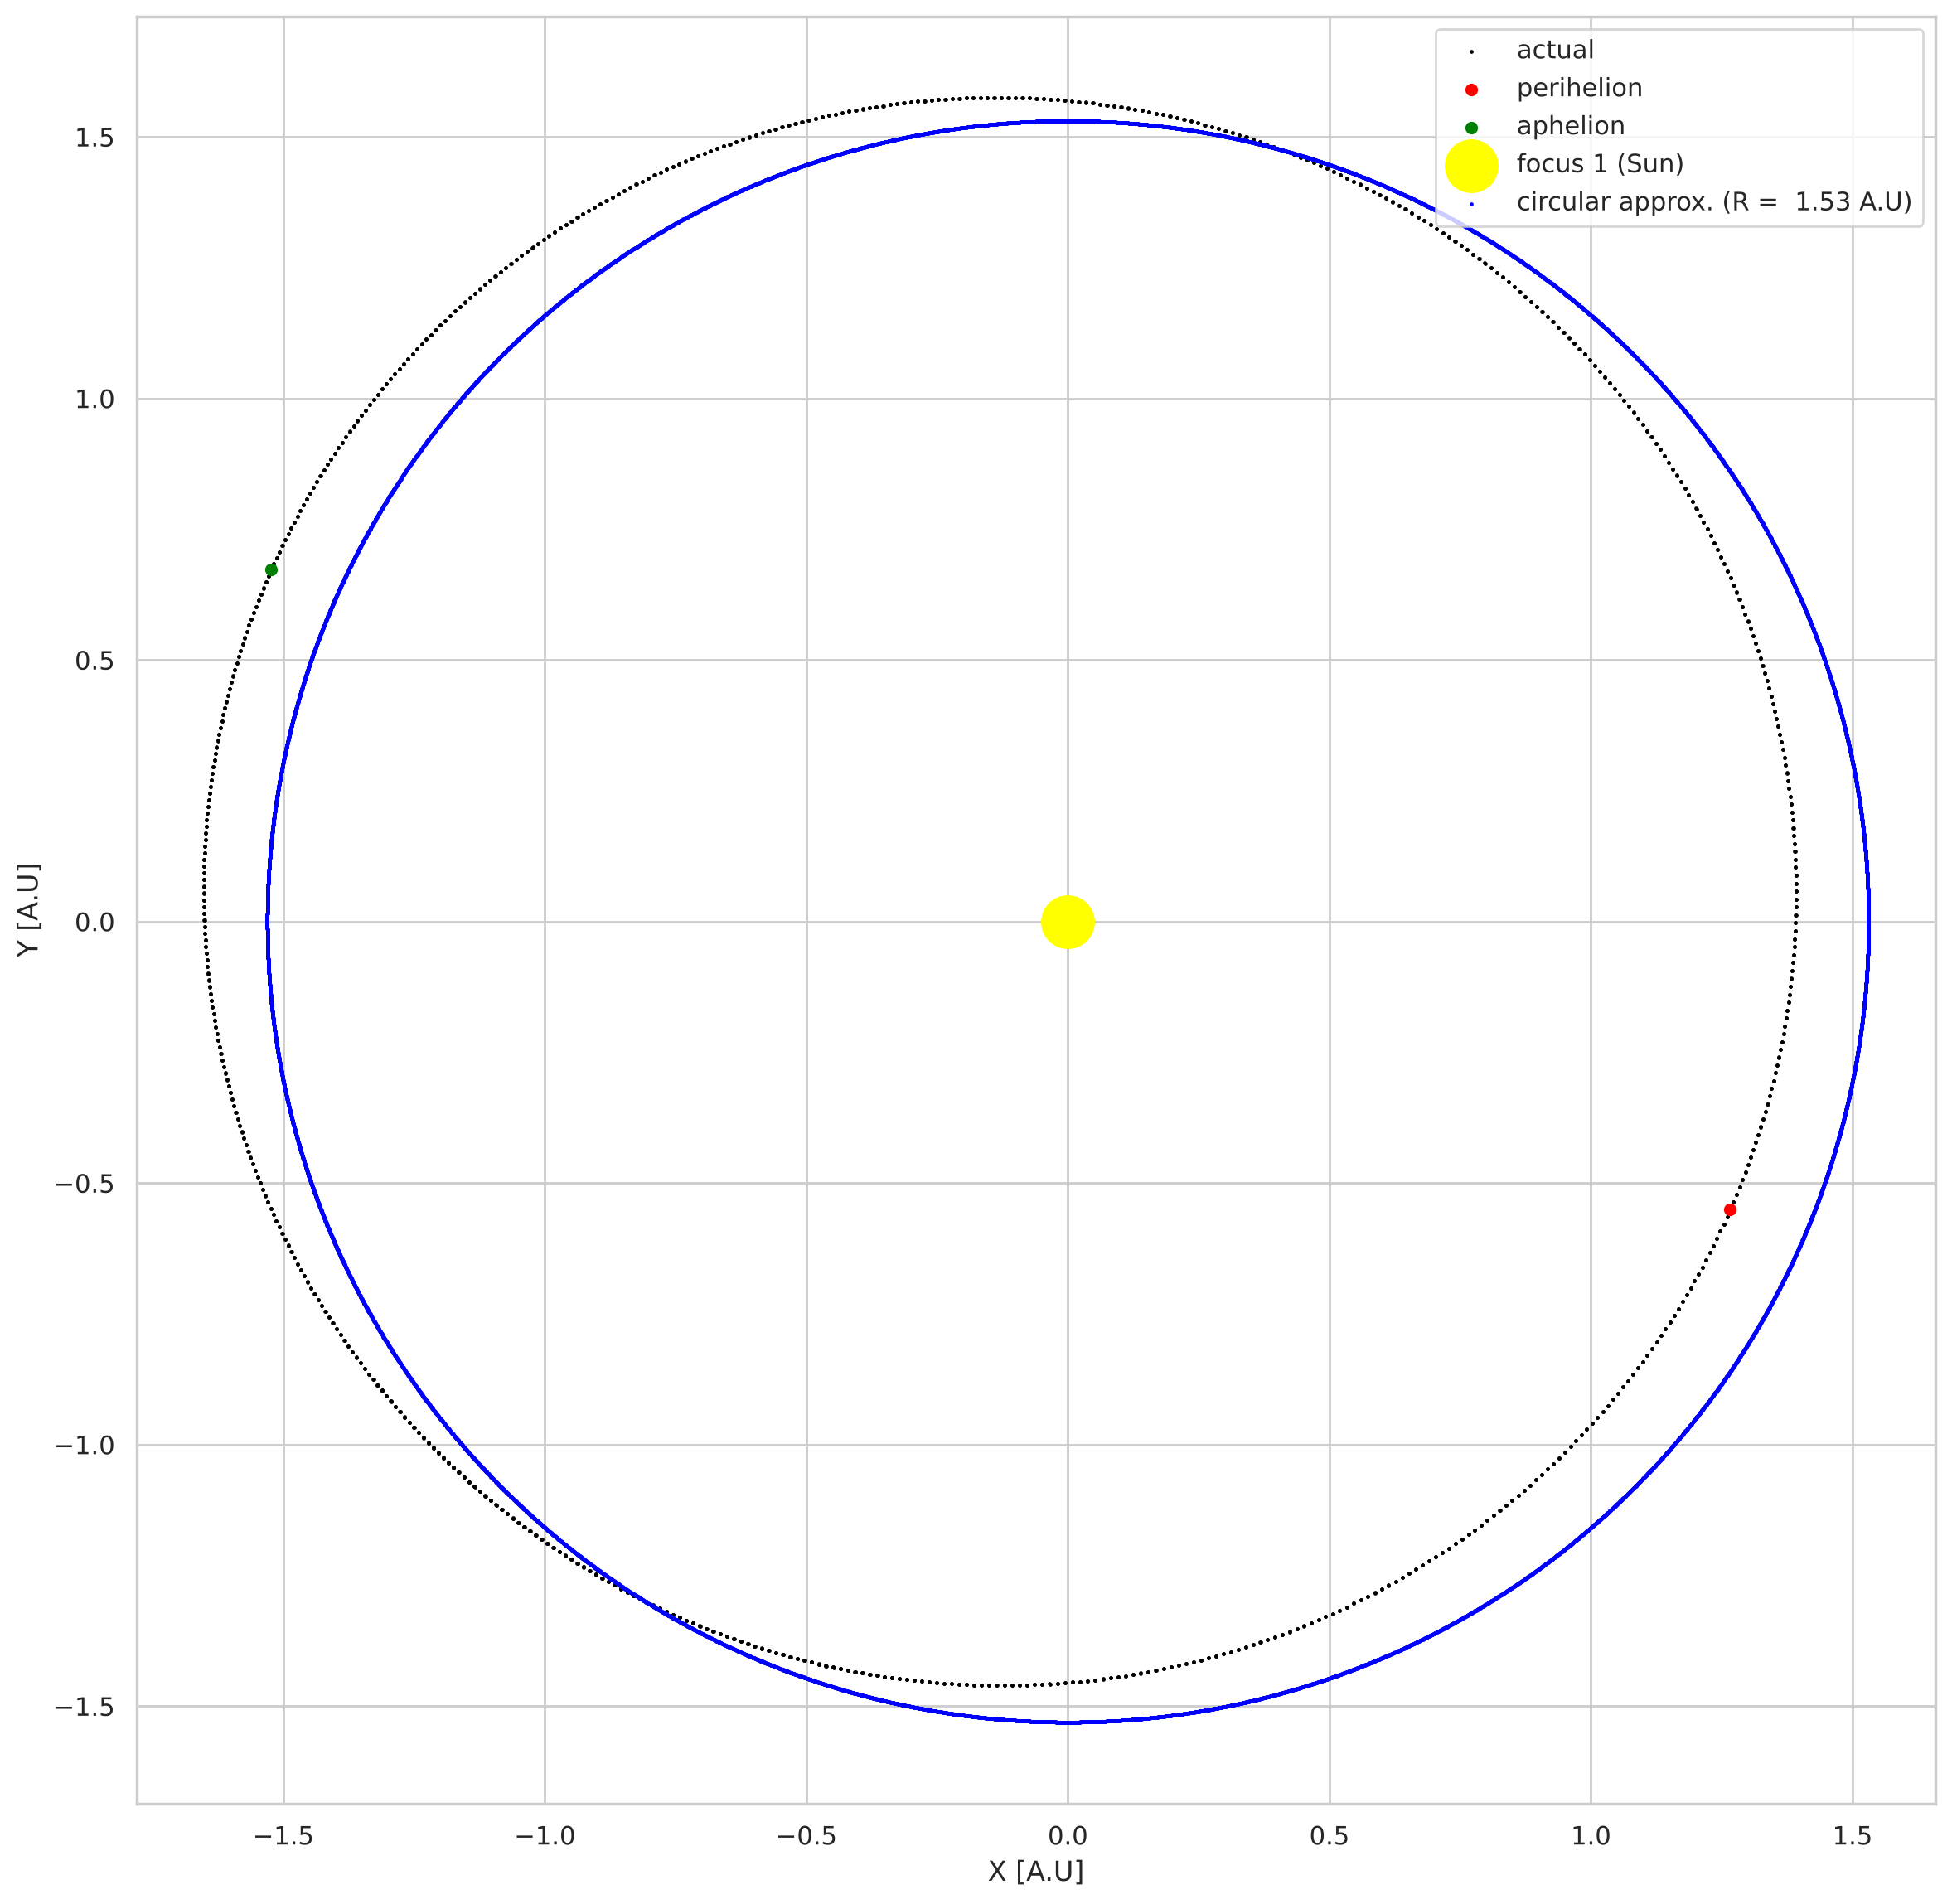

In [8]:
perihelion, aphelion = get_perihelion_aphelion(df)

plt.figure(figsize=(14, 14))
plt.scatter(df["X"], df["Y"], s=0.5, color="black", label="actual")

plt.scatter(perihelion["X"], perihelion["Y"], s=20, color="red", label="perihelion")
plt.scatter(aphelion["X"], aphelion["Y"], s=20, color="green", label="aphelion")
plt.scatter(0, 0, s=500, color="yellow", label="focus 1 (Sun)")
plt.xlabel("X [A.U]")
plt.ylabel("Y [A.U]")
plt.axis("equal")


r = df["R"].mean()
theta = np.linspace(0, 2*np.pi, 10000)
X_, Y_ = r*np.cos(theta), r*np.sin(theta)
plt.scatter(X_, Y_, s=0.5, color="blue", label=f"circular approx. (R = {r: .2f} A.U)")
plt.legend(loc="upper right")
plt.savefig(f"plots/comparing_the_orbit_with_circle_{planet_}.png", dpi=150, bbox_inches='tight')

# Kepler's First Law: 
The Orbit is an Ellipse

## Computing the orbital parameters

In [9]:
R_min = df["R"].min()
R_max = df["R"].max()
e = (R_max - R_min)/(R_max + R_min)
p = (2*R_max*R_min)/(R_max + R_min)

a = (R_max + R_min) / 2
b = np.sqrt(R_max*R_min)
c = a * e

print(f"R_min = {R_min:.4f} AU  (perihelion distance)")
print(f"R_max = {R_max:.4f} AU  (aphelion distance)")
print(f"a     = {a:.4f} AU  (semi-major axis)")
print(f"b     = {b:.4f} AU  (semi-minor axis)")
print(f"c     = {c:.4f} AU  (focal distance)")
print(f"e     = {e:.4f}      (eccentricity: 0=circle, 1=parabola)")
print(f"p     = {p:.4f} AU  (semi-latus rectum)")

R_min = 1.3813 AU  (perihelion distance)
R_max = 1.6660 AU  (aphelion distance)
a     = 1.5236 AU  (semi-major axis)
b     = 1.5170 AU  (semi-minor axis)
c     = 0.1423 AU  (focal distance)
e     = 0.0934      (eccentricity: 0=circle, 1=parabola)
p     = 1.5103 AU  (semi-latus rectum)


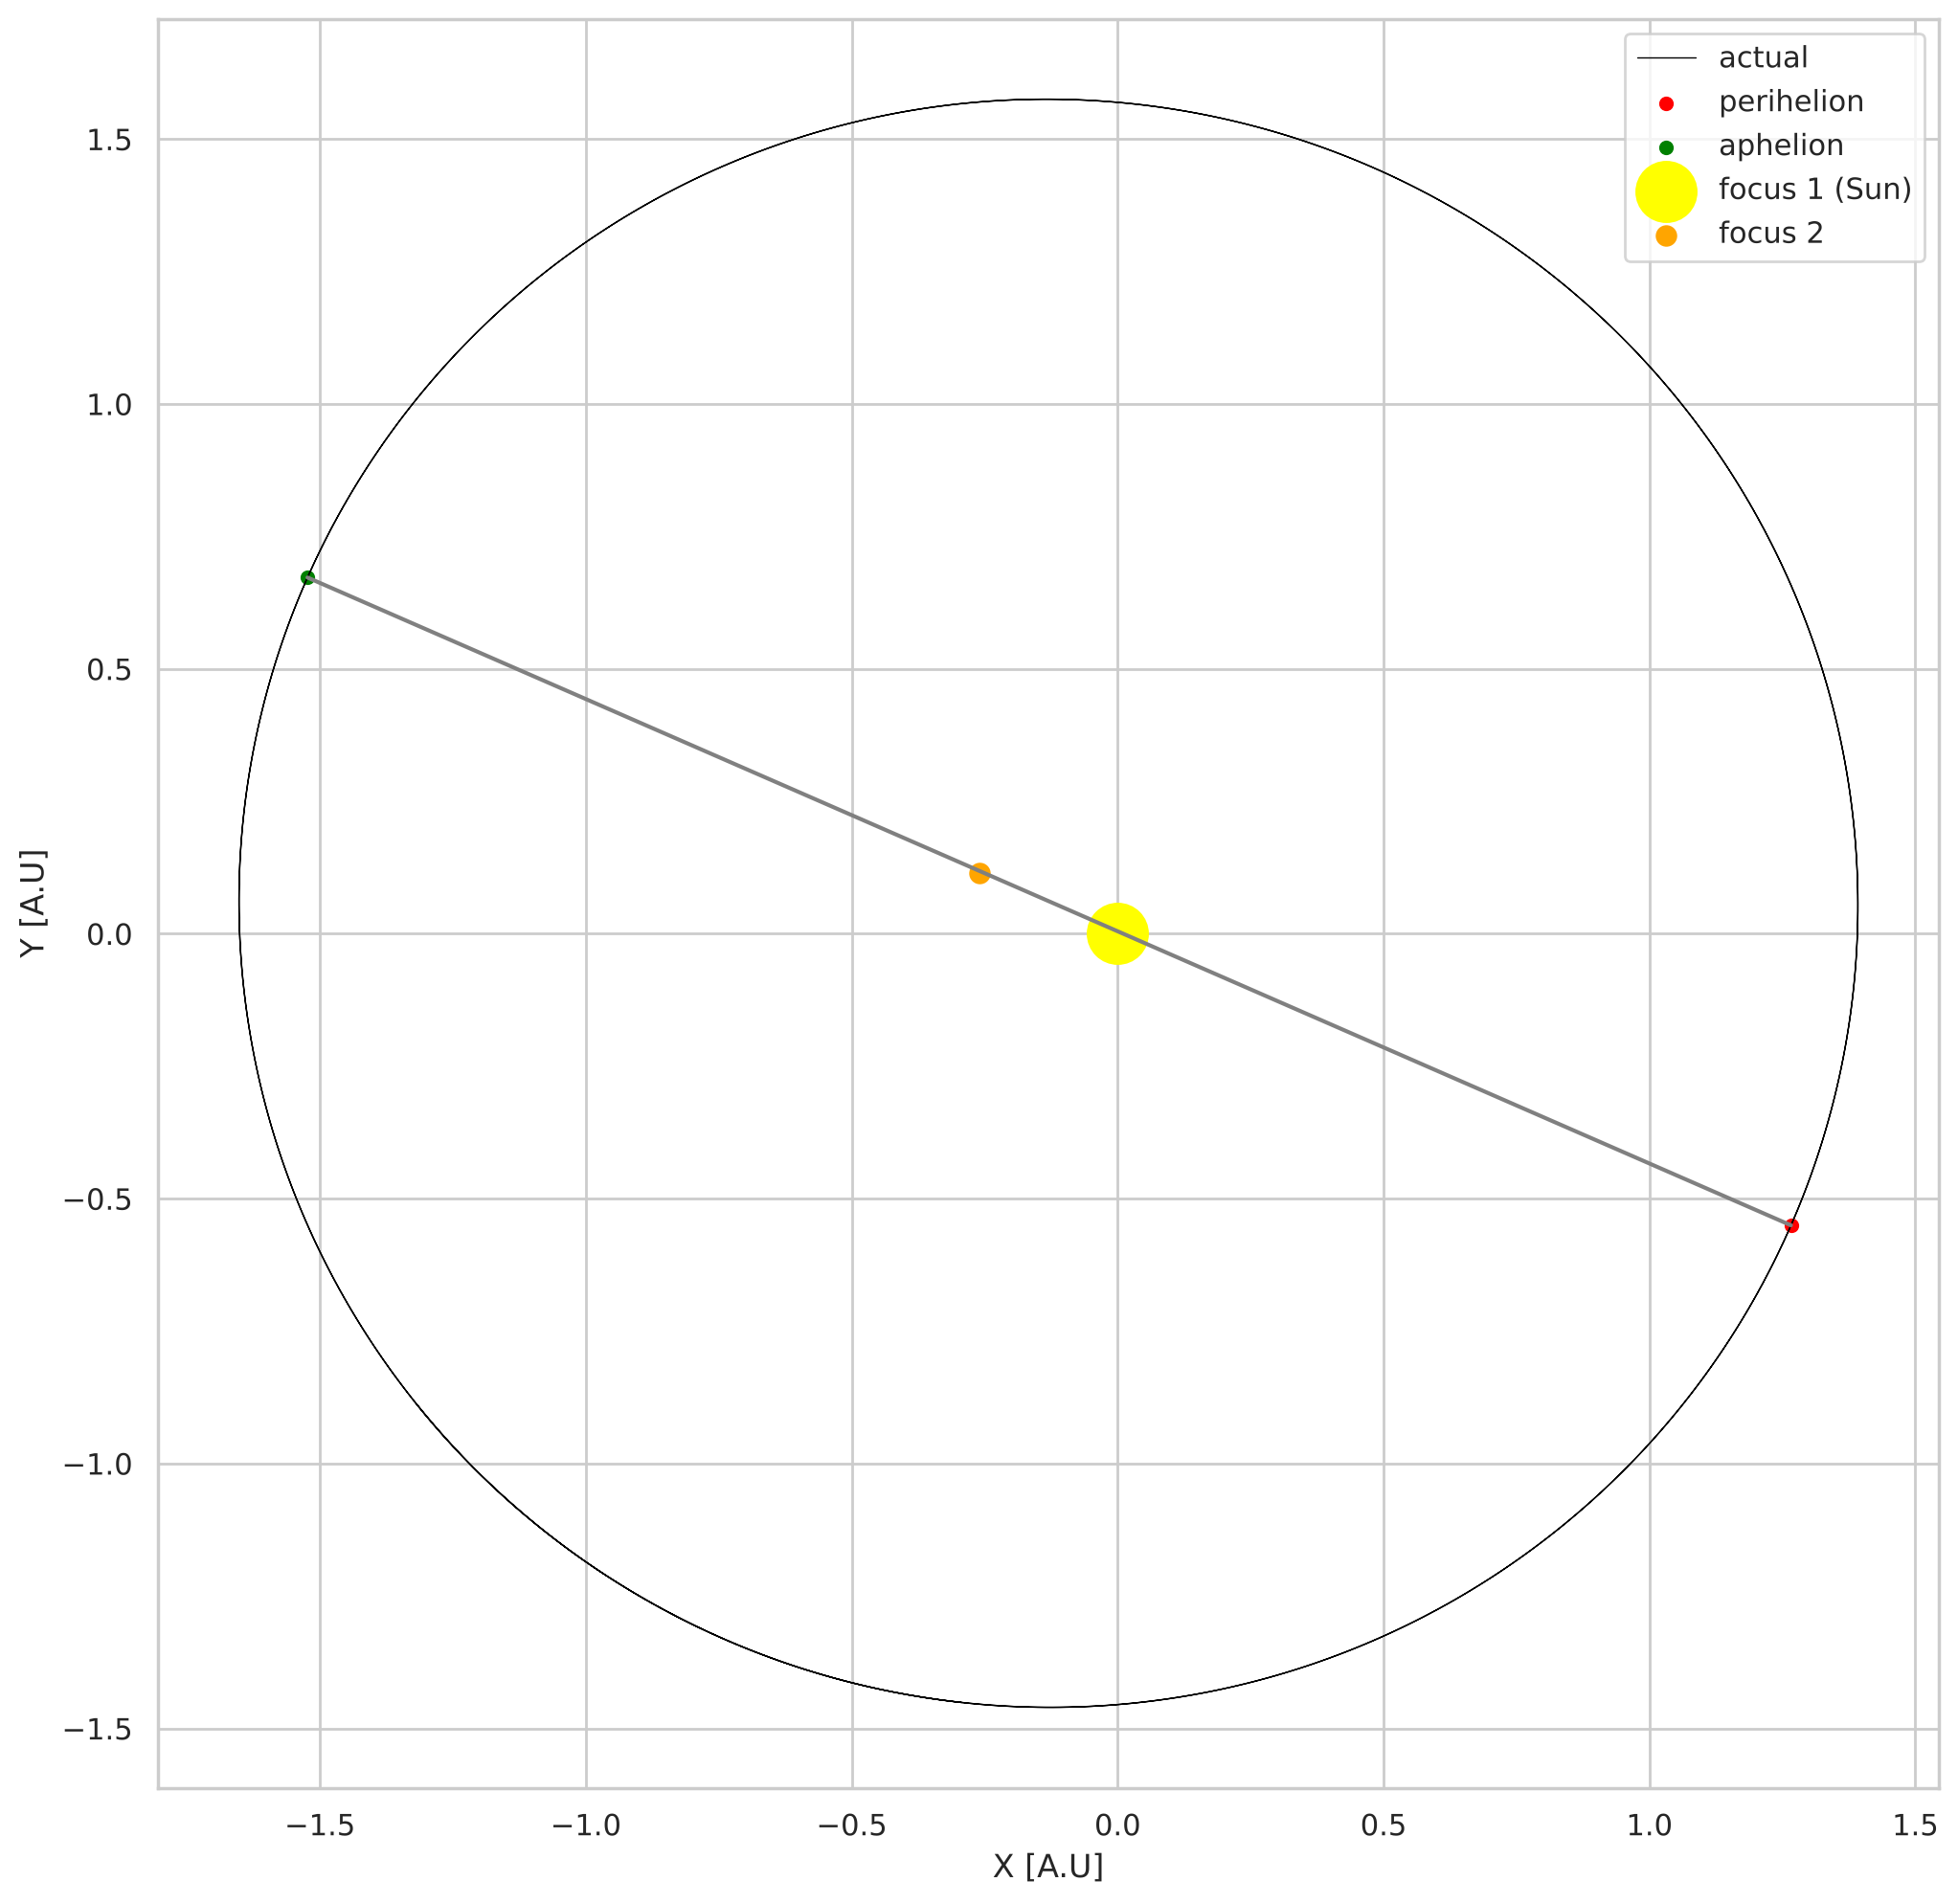

In [10]:
plt.figure(figsize=(12, 12))
plt.plot(df["X"], df["Y"], color="black", label="actual", lw=0.5)

plt.scatter(perihelion["X"], perihelion["Y"], s=20, color="red", label="perihelion")
plt.scatter(aphelion["X"], aphelion["Y"], s=20, color="green", label="aphelion")
plt.scatter(0, 0, s=500, color="yellow", label="focus 1 (Sun)")
plt.plot([perihelion["X"], aphelion["X"]], [perihelion["Y"], aphelion["Y"]], color="gray")
plt.xlabel("X [A.U]")
plt.ylabel("Y [A.U]")
plt.axis("equal")


direction = np.array([aphelion["X"], aphelion["Y"]])
unit_direction = direction/np.linalg.norm(direction)
focus = 2*c*unit_direction 

plt.scatter(focus[0], focus[1], s=50, color="orange", label="focus 2")

plt.legend(loc="upper right")
plt.savefig(f"plots/keeping_sun_at_one_focus_{planet_}.png", dpi=150, bbox_inches='tight')

## Fit the polar ellipse equation 

### train-test split

In [11]:
theta_perihelion = np.arctan2(perihelion["Y"], perihelion["X"])
df["theta"] = np.arctan2(df["Y"], df["X"]) - theta_perihelion
df["cos t"] = np.cos(df["theta"])
df["1/r"] = 1/df["R"]

training_size = 0.8
train_df = df[["cos t", "1/r"]].iloc[0: int(len(df)*training_size), :]
test_df = df[["cos t", "1/r"]].iloc[int(len(df)*training_size):, ]
display(train_df.head())
print(train_df.shape, test_df.shape)


X_train = train_df[["cos t"]].values
X_test = test_df[["cos t"]].values
y_train = train_df["1/r"].values
y_test = test_df["1/r"].values

,cos t,1/r
date,,
2020-01-01,-0.539423,0.629013
2020-01-02,-0.532359,0.629452
2020-01-03,-0.525248,0.629894
2020-01-04,-0.518091,0.630339
2020-01-05,-0.510886,0.630786


(1169, 2) (293, 2)


### linear regression

In [12]:
reg = LinearRegression()
reg.fit(X_train, y_train)
y_pred = reg.predict(X_test)

p_fit = 1 / reg.intercept_
e_fit = reg.coef_[0] * p_fit

print(f"p fitted = {p_fit:.4f} AU ")
print(f"e fitted = {e_fit:.4f}")

p fitted = 1.5104 AU 
e fitted = 0.0934


### plotting fitted ellipse over actual ellipse

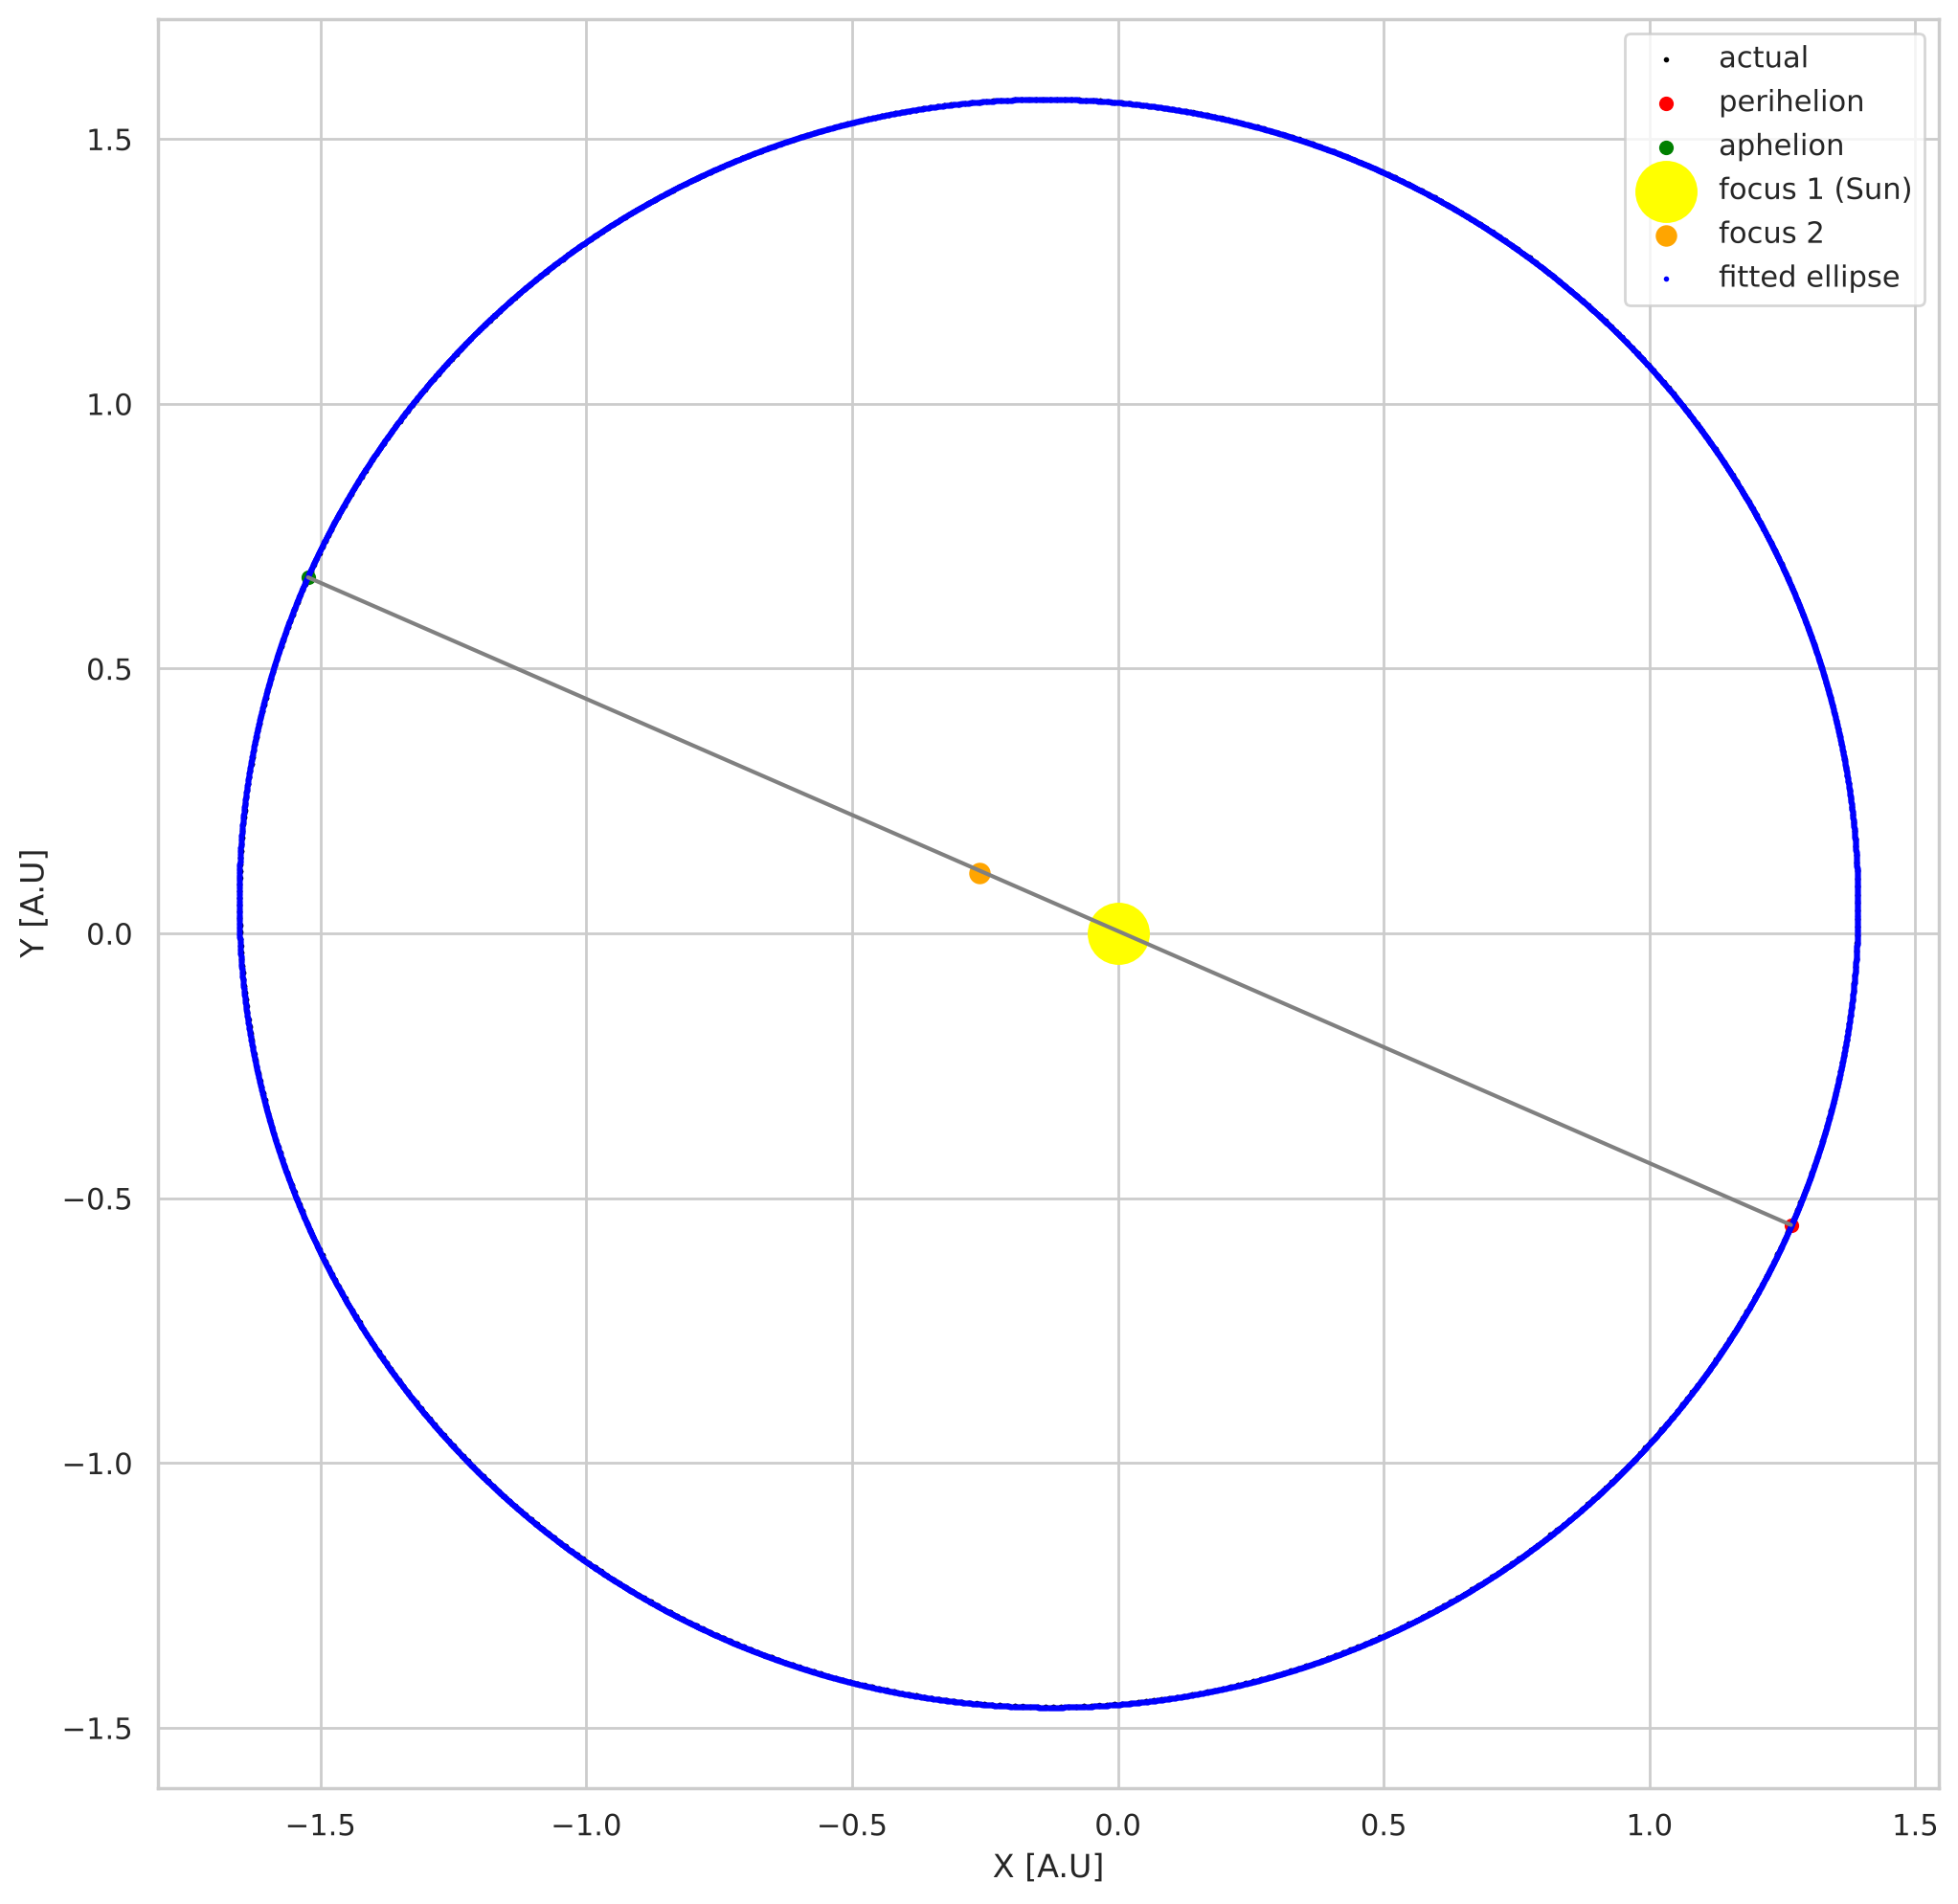

In [13]:
plt.figure(figsize=(12, 12))
plt.scatter(df["X"], df["Y"], s=1, color="black", label="actual")

plt.scatter(perihelion["X"], perihelion["Y"], s=20, color="red", label="perihelion")
plt.scatter(aphelion["X"], aphelion["Y"], s=20, color="green", label="aphelion")
plt.scatter(0, 0, s=500, color="yellow", label="focus 1 (Sun)")
plt.plot([perihelion["X"], aphelion["X"]], [perihelion["Y"], aphelion["Y"]], color="gray")
plt.xlabel("X [A.U]")
plt.ylabel("Y [A.U]")
plt.axis("equal")


direction = np.array([aphelion["X"], aphelion["Y"]])
unit_direction = direction/np.linalg.norm(direction)
focus = 2*c*unit_direction 

plt.scatter(focus[0], focus[1], s=50, color="orange", label="focus 2")






theta_range = np.linspace(0, 2*np.pi, 10000)
r_predicted = p_fit / (1 + e_fit * np.cos(theta_range))

X_predicted = r_predicted * np.cos(theta_range+theta_perihelion)
Y_predicted = r_predicted * np.sin(theta_range+theta_perihelion)
plt.scatter(X_predicted, Y_predicted, s=1, color="blue", label="fitted ellipse")

plt.legend(loc="upper right")

plt.savefig(f"plots/recover_orbit_using_linear_regression_on_parametric_equation_{planet_}.png", dpi=150, bbox_inches='tight')

# Kepler's Second Law: 
Equal Areas in Equal Times

## Computing areas

Mean area : 0.010570370672983685 AU^2/day
Std  area : 2.032764067775017e-07
Variation (area): 0.0019230773741648088%


Text(0, 0.5, 'area swept each day')

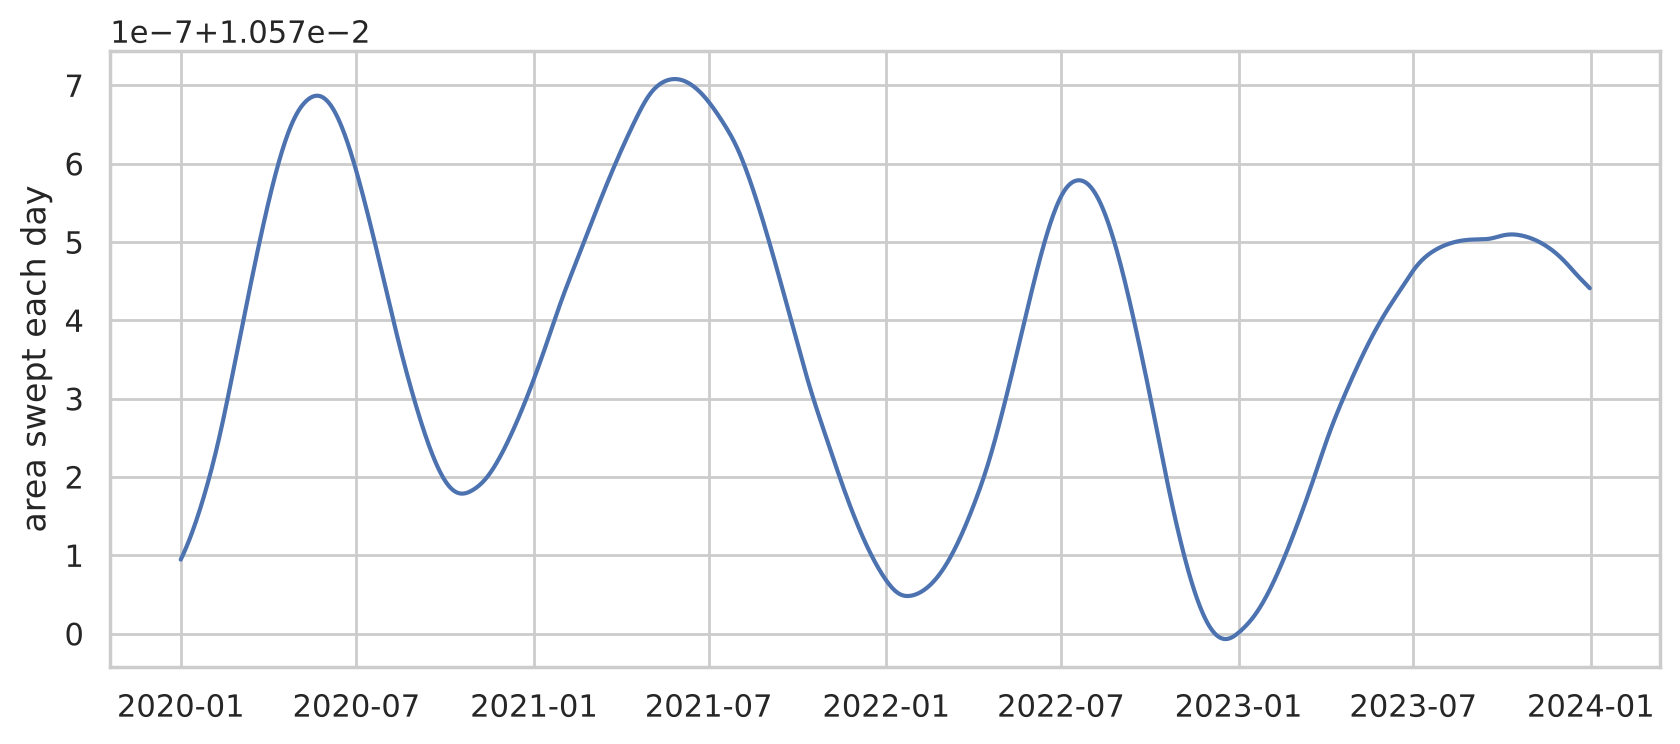

In [14]:
areas = []
for i in range(len(df)-1):
    r1 = df[["X", "Y", "Z"]].values[i, :]
    r2 = df[["X", "Y", "Z"]].values[i+1, :]
    areas.append(np.linalg.norm(np.cross(r1, r2)) / 2)
areas.append(np.nan)
df["area"] = areas

print(f"Mean area : {df['area'].mean()} AU^2/day")
print(f"Std  area : {df['area'].std()}")
print(f"Variation (area): {100 * df['area'].std() / df['area'].mean()}%")

plt.figure(figsize=(10, 4))
plt.plot(df.index, areas)
plt.ylabel("area swept each day")

## Computing angular momentum
$L = r \times v$

In [15]:
r_x, r_y, r_z, v_x, v_y, v_z = symbols("r_x, r_y, r_z, v_x, v_y, v_z")
r = Matrix([r_x, r_y, r_z])
v = Matrix([v_x, v_y, v_z])

L = r.cross(v).subs({v_z: 0, r_z: 0})
L

Matrix([
[                0],
[                0],
[r_x*v_y - r_y*v_x]])

Mean Lz : 0.021130044567331117 AU^2/day
Std  Lz : 4.0762176713469316e-07
Variation (Lz): 0.0019291098314336346%


Text(0, 0.5, 'Lz')

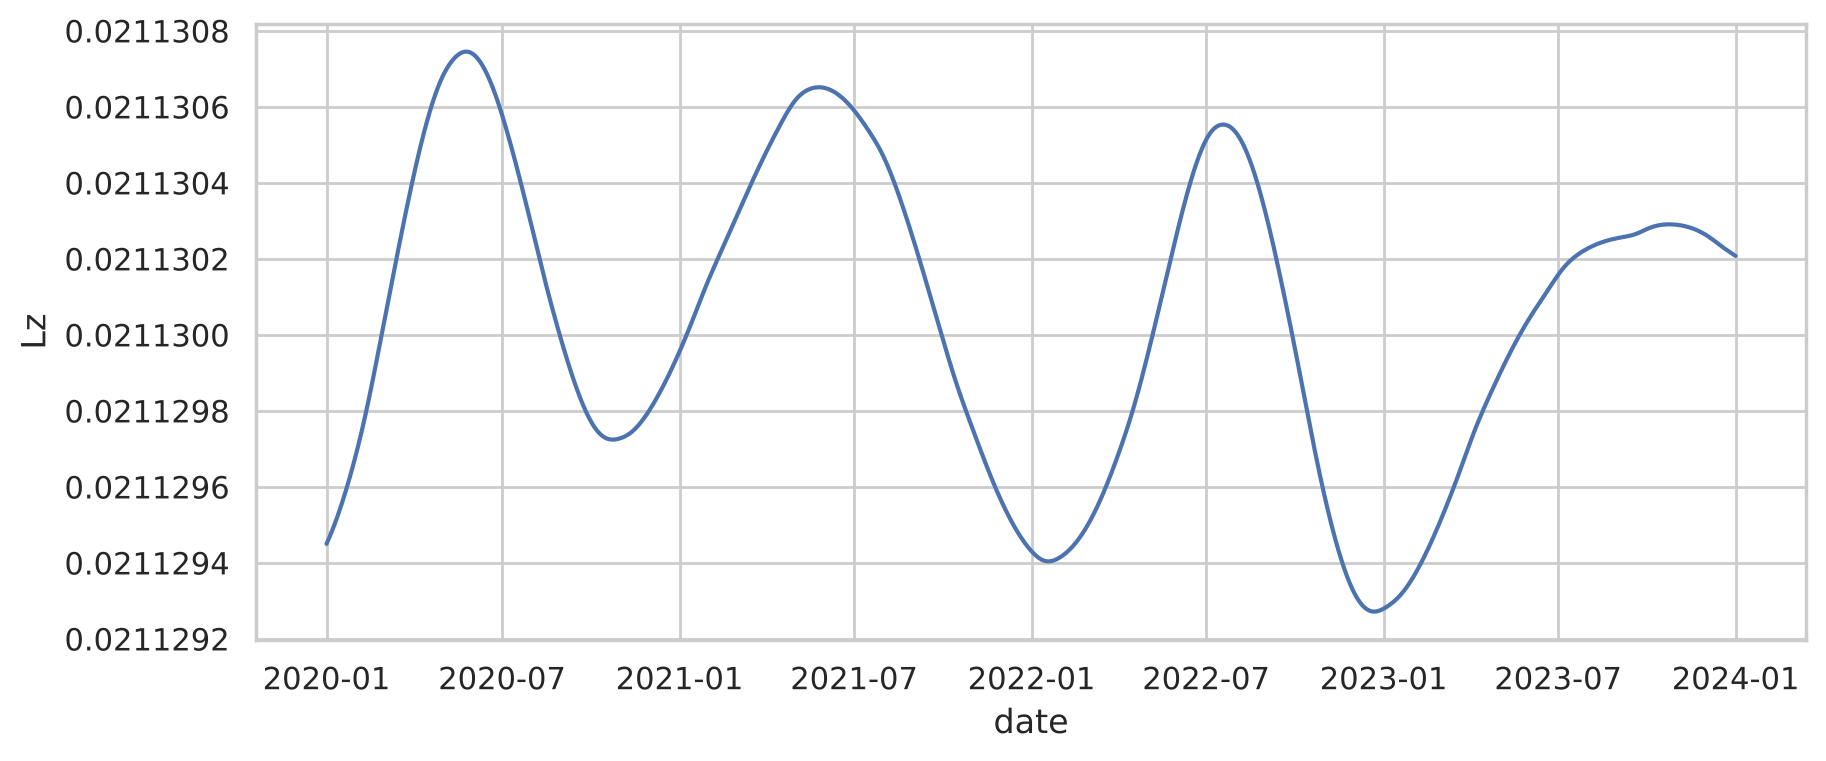

In [16]:
df["Lz"] = df["X"]*df["VY"] - df["Y"]*df["VX"]

print(f"Mean Lz : {df['Lz'].mean()} AU^2/day")
print(f"Std  Lz : {df['Lz'].std()}")
print(f"Variation (Lz): {100 * df['Lz'].std() / df['Lz'].mean()}%")

plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x=df.index, y="Lz")
plt.ylabel("Lz")

## Equal areas in equal times: two 27-day windows
The radius vector sweeps the same area whether Mars is near perihelion (fast) or near aphelion (slow).

In [17]:
print(f"Area swept, days 40-67 : {get_area_swept(40, 27):.5f} AU^2")
print(f"Area swept, days 99-126: {get_area_swept(99, 27):.5f} AU^2")

Area swept, days 40-67 : 0.28540 AU^2
Area swept, days 99-126: 0.28541 AU^2


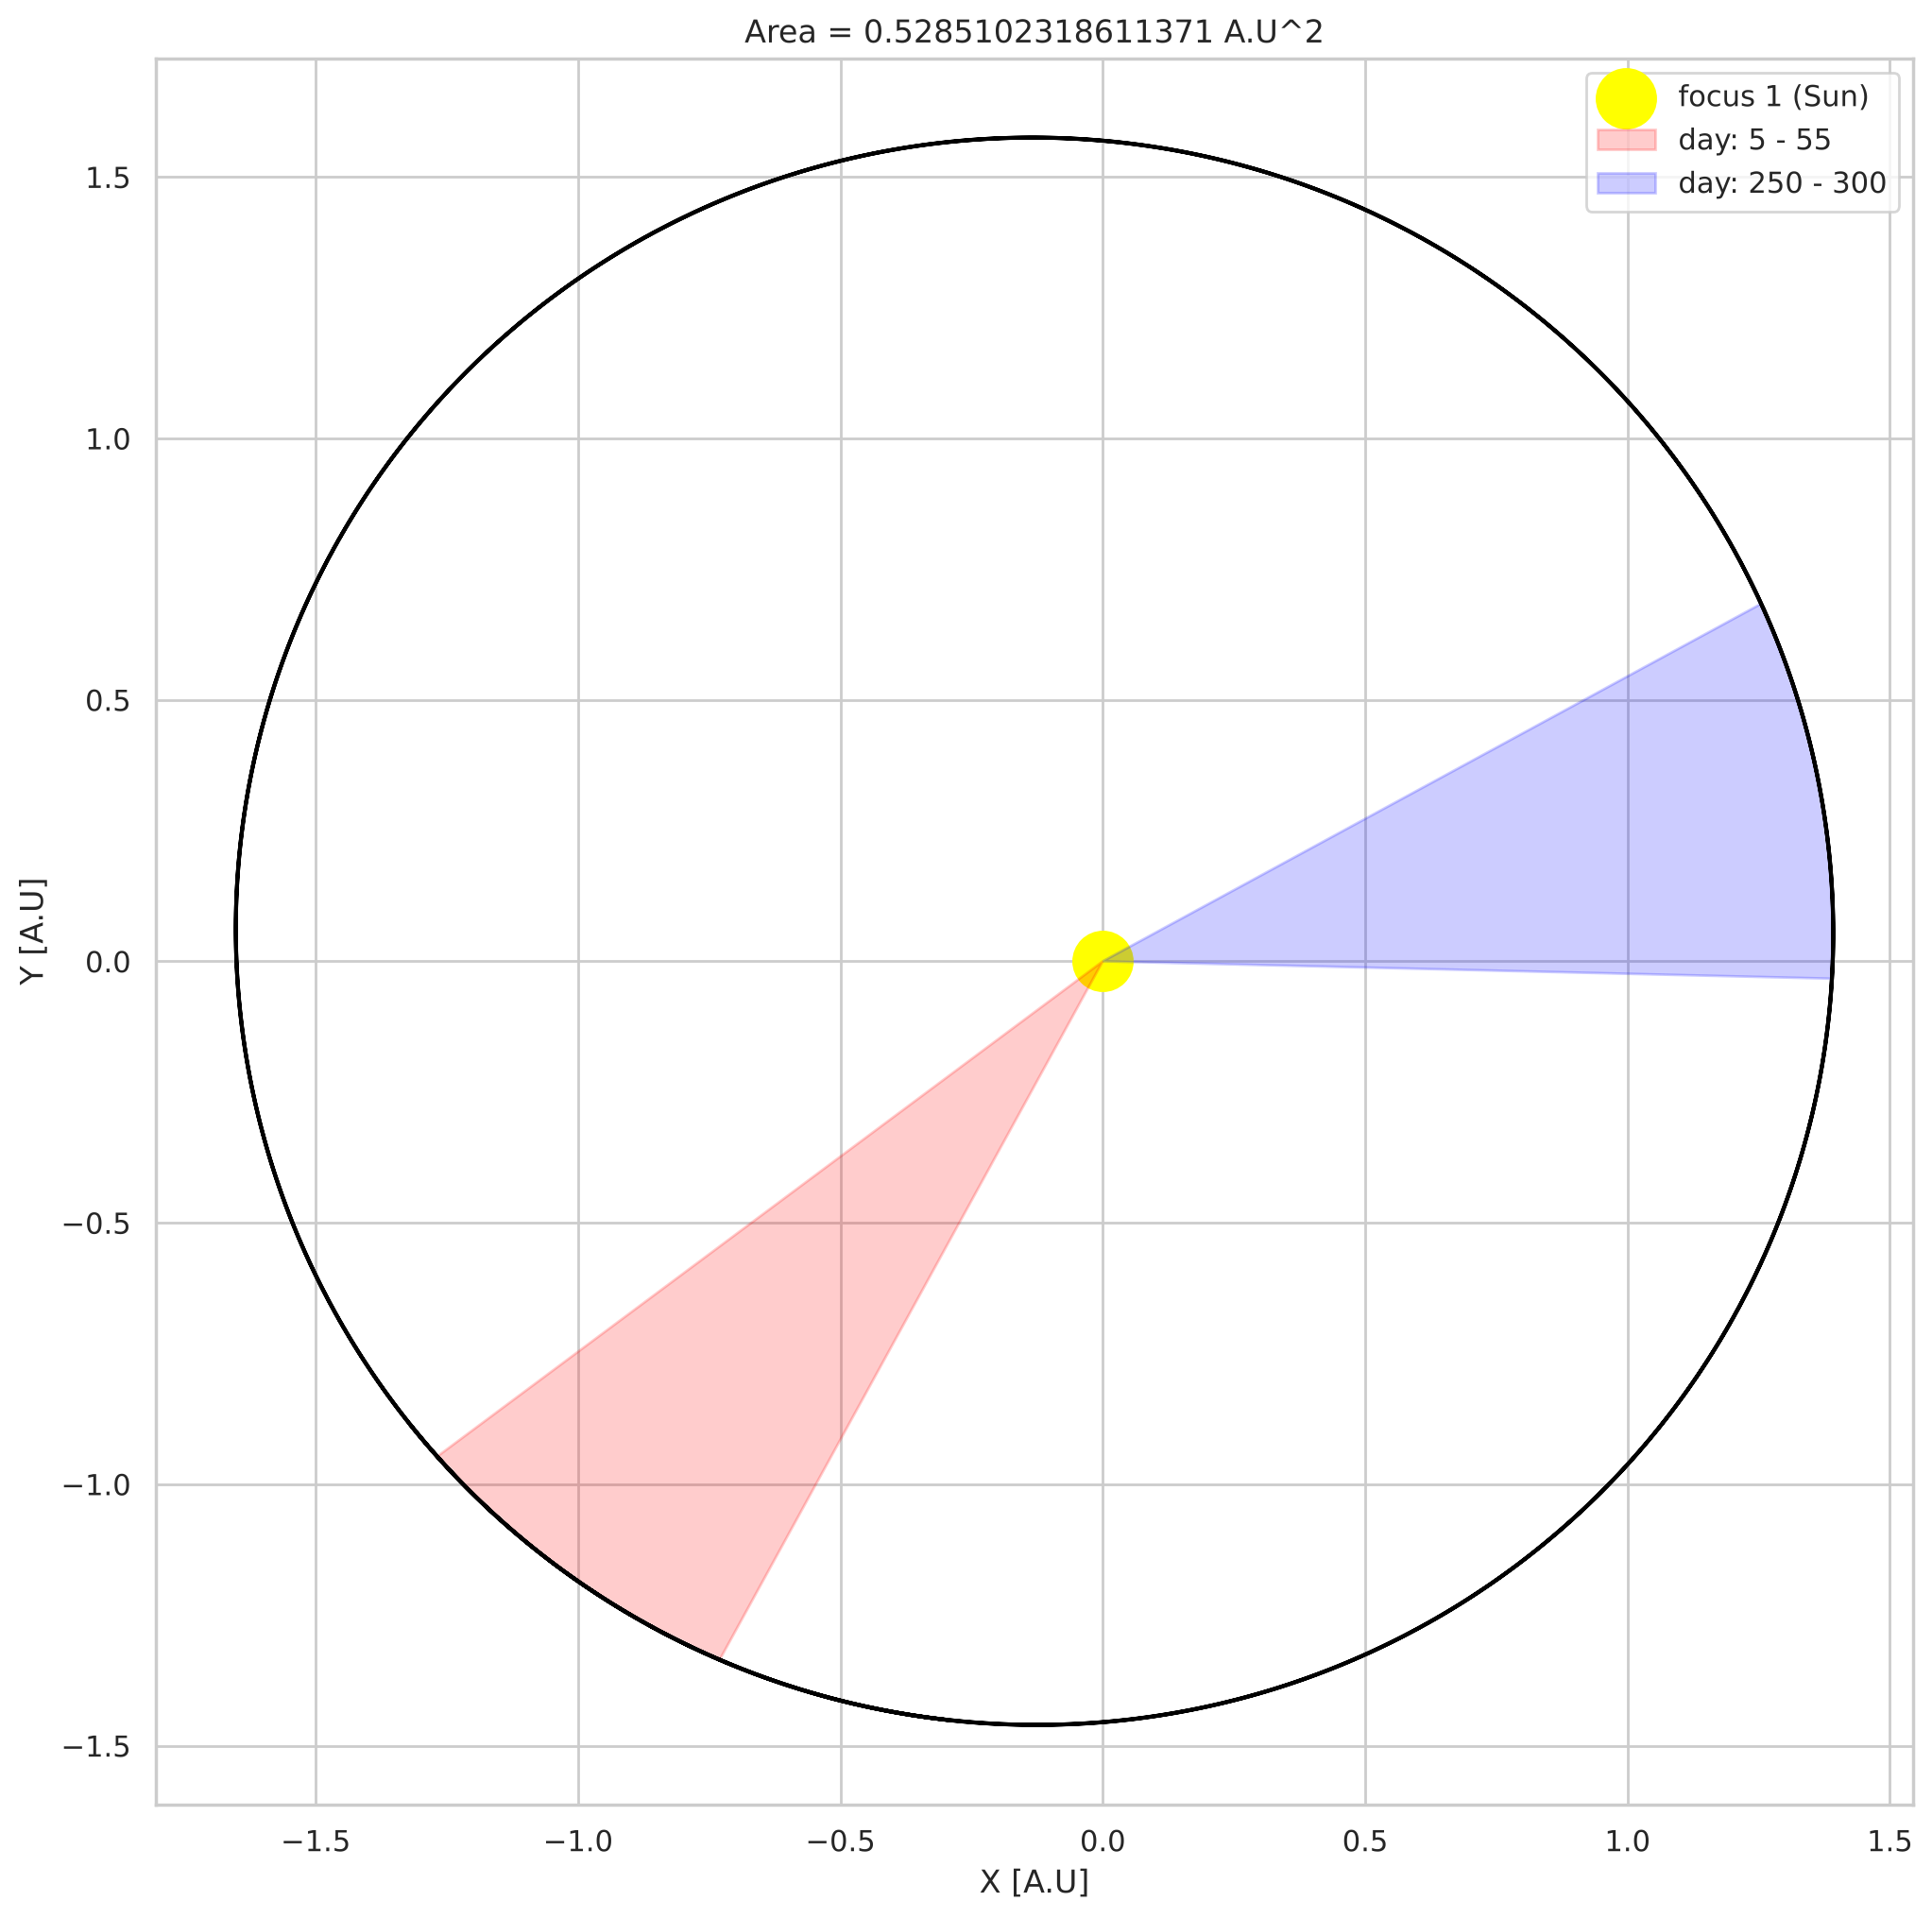

In [18]:




plt.figure(figsize=(12, 12))
plt.plot(df["X"], df["Y"], color="black")
plt.scatter(0, 0, s=500, color="yellow", label="focus 1 (Sun)")

plot_area_swept(5, 50, color="red")
plot_area_swept(250, 50, color="blue")
plt.savefig(f"plots/equal_area_in_equal_time_{planet_}.png", dpi=150, bbox_inches='tight')

# Kepler's Third Law: 
$ T^2 \propto a^3$

## Estimate orbital period T from consecutive aphelion passages

In [19]:
planets = ["mercury", "venus", "earth", "mars"]#, "jupiter", "saturn", "uranus", "neptune"]
planets_df = {planet: get_planet_df(planet) for planet in planets}

orbital_params = {planet: {"T": get_time_period(planet), "a": get_semi_major_axis(planet)} for planet in planets}

orbital_params_df = pd.DataFrame(orbital_params).T
orbital_params_df

,T,a
mercury,88.0,0.387098
venus,224.6,0.723327
earth,366.0,0.999987
mars,687.0,1.523630


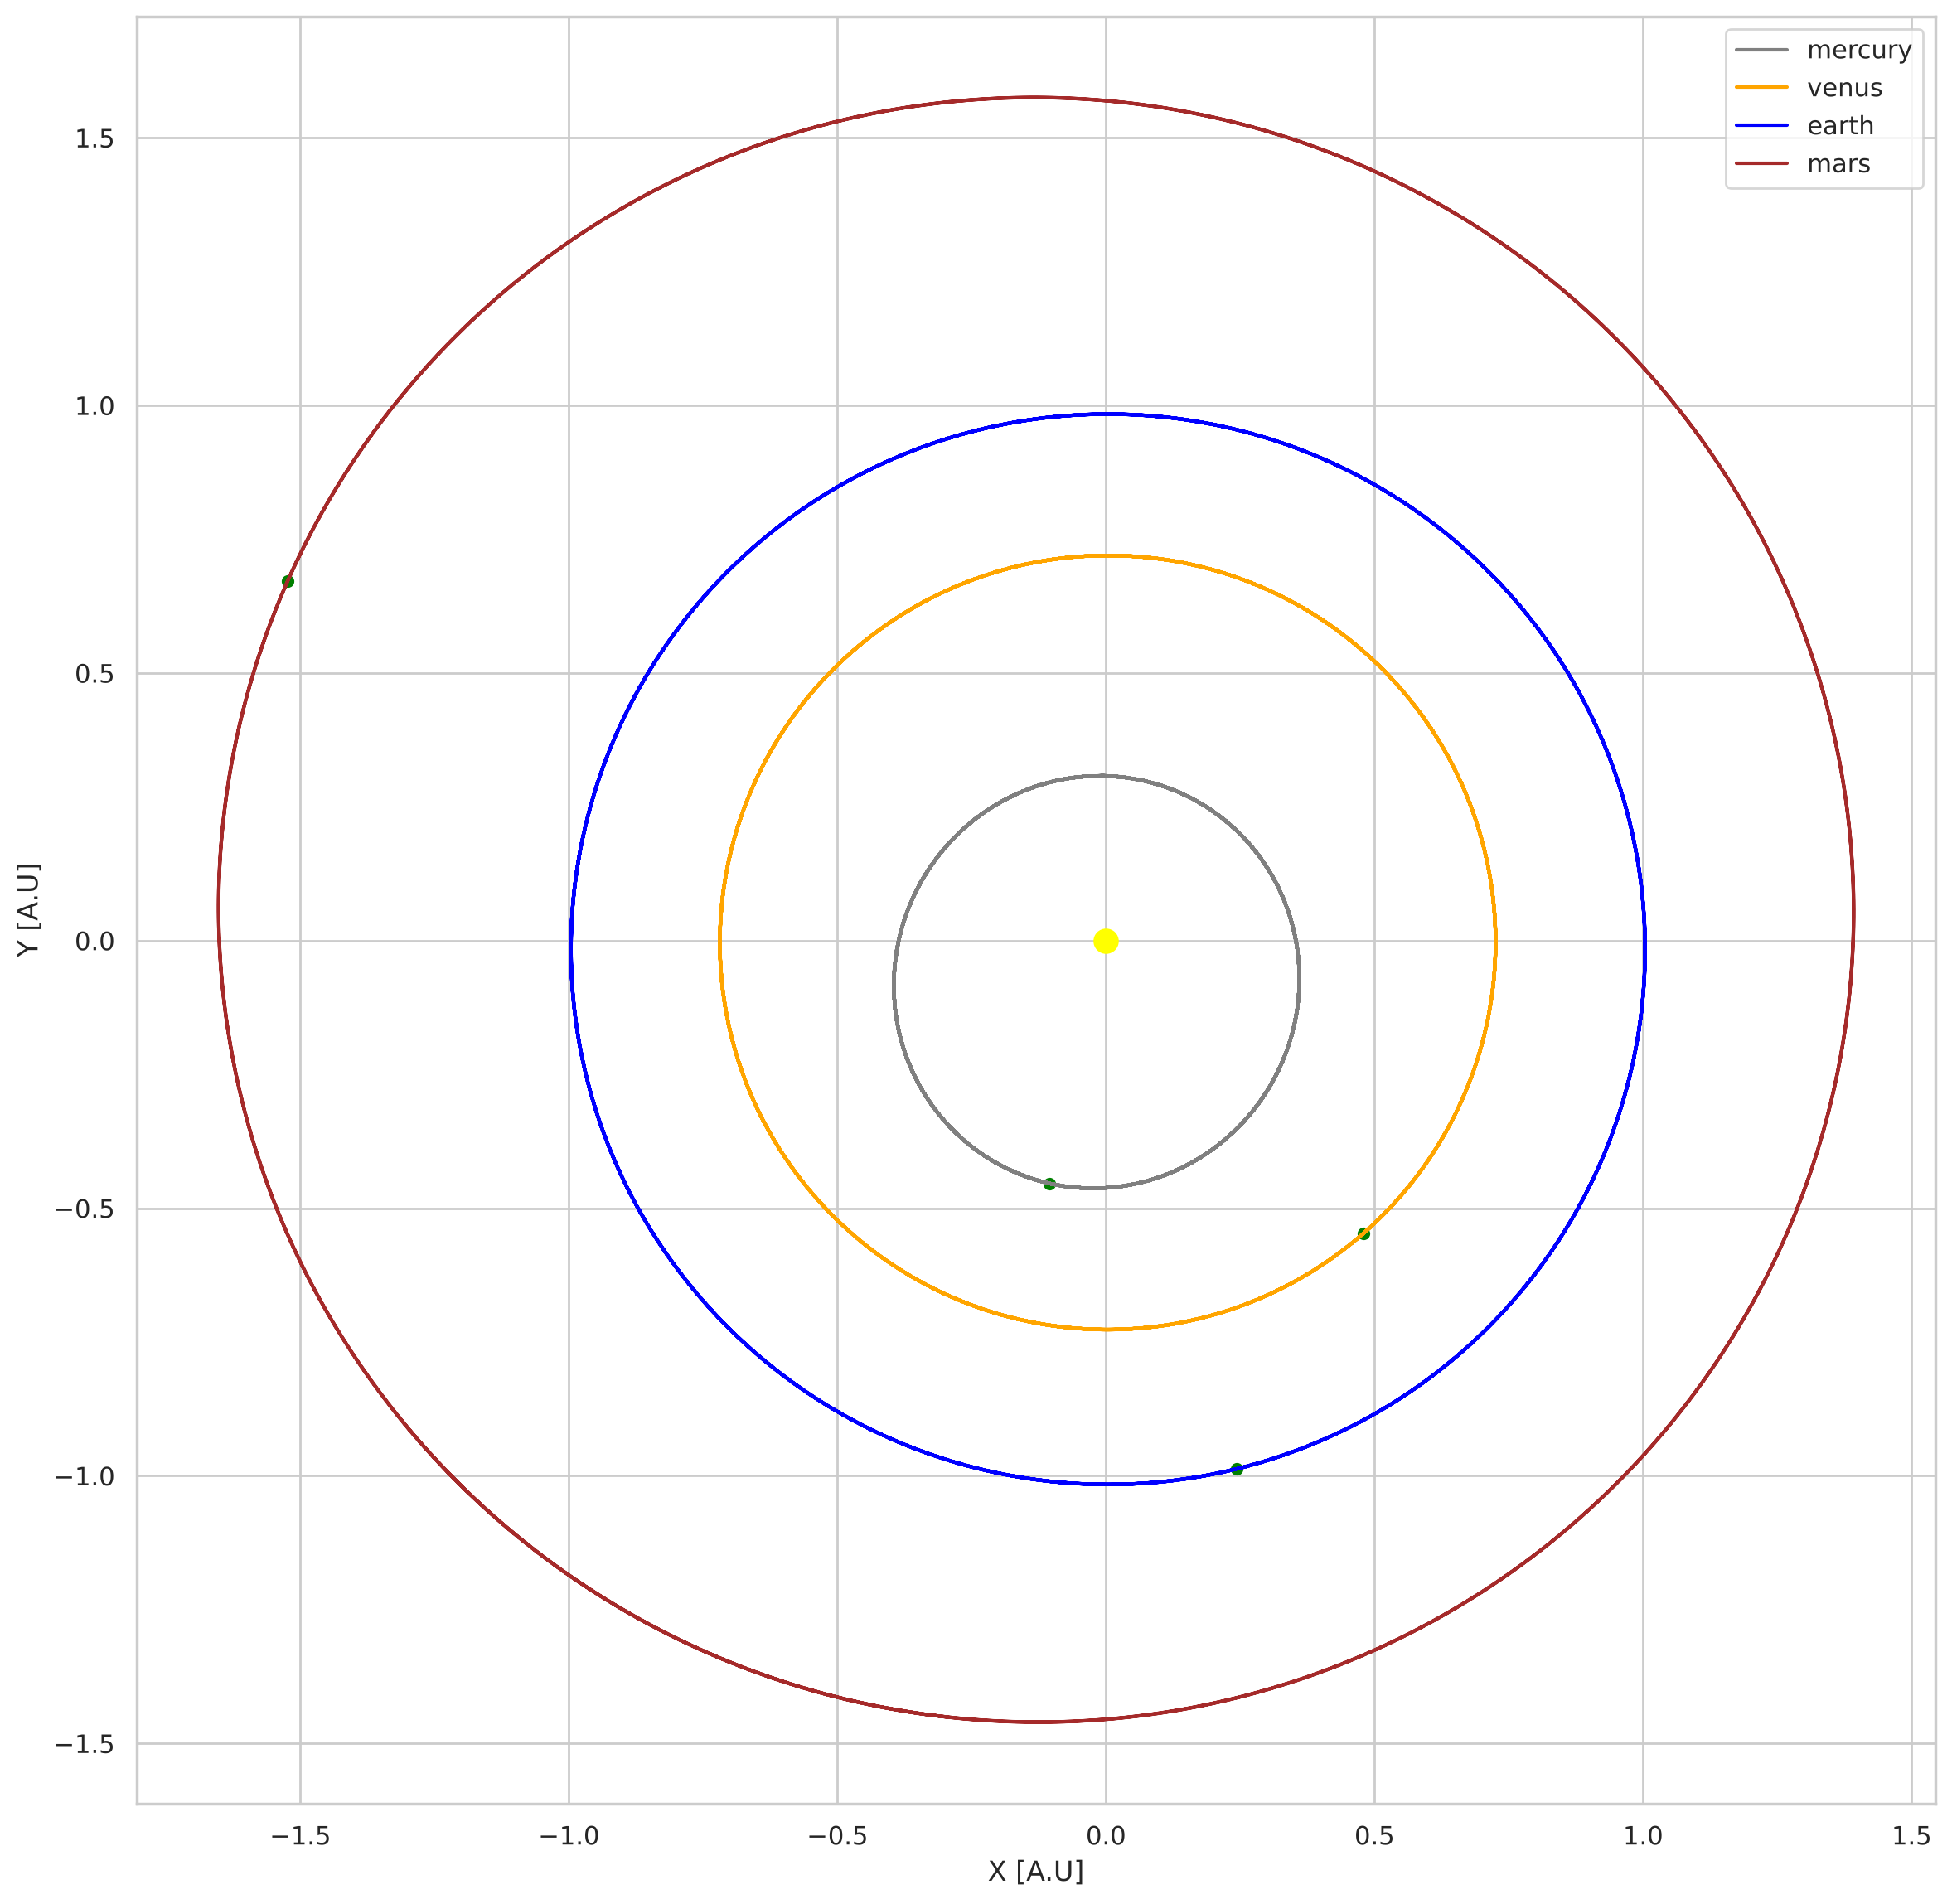

In [20]:
plt.figure(figsize=(14, 14))
for planet in planets:
    plt.plot(planets_df[planet]["X"], planets_df[planet]["Y"], color=planet_colors[planet], label=planet)
    perihelion_, aphelion_ = get_perihelion_aphelion(planets_df[planet])
    plt.scatter(aphelion_["X"], aphelion_["Y"], s=20, color="green")
plt.scatter(0, 0, s=100, color="yellow")
plt.xlabel("X [A.U]")
plt.ylabel("Y [A.U]")
plt.axis("equal")
plt.legend()
plt.savefig(f"plots/orbits_inner_planets.png", dpi=150, bbox_inches='tight');

## Verify $\frac{T^2}{a^3}$ is constant across all planets

In [21]:
orbital_params_df["T^2/a^3"] = (orbital_params_df["T"]**2)/(orbital_params_df["a"]**3)
orbital_params_df

,T,a,T^2/a^3
mercury,88.0,0.387098,133506.245651
venus,224.6,0.723327,133295.352968
earth,366.0,0.999987,133961.410305
mars,687.0,1.523630,133436.462004


## Plot log(T) vs log(a) - slope should be 3/2

,T,a
mercury,88.0,0.387098
venus,224.6,0.723327
earth,366.0,0.999987
mars,687.0,1.523630


Slope: 1.500283885368373
Intercept: 2.562847609975649


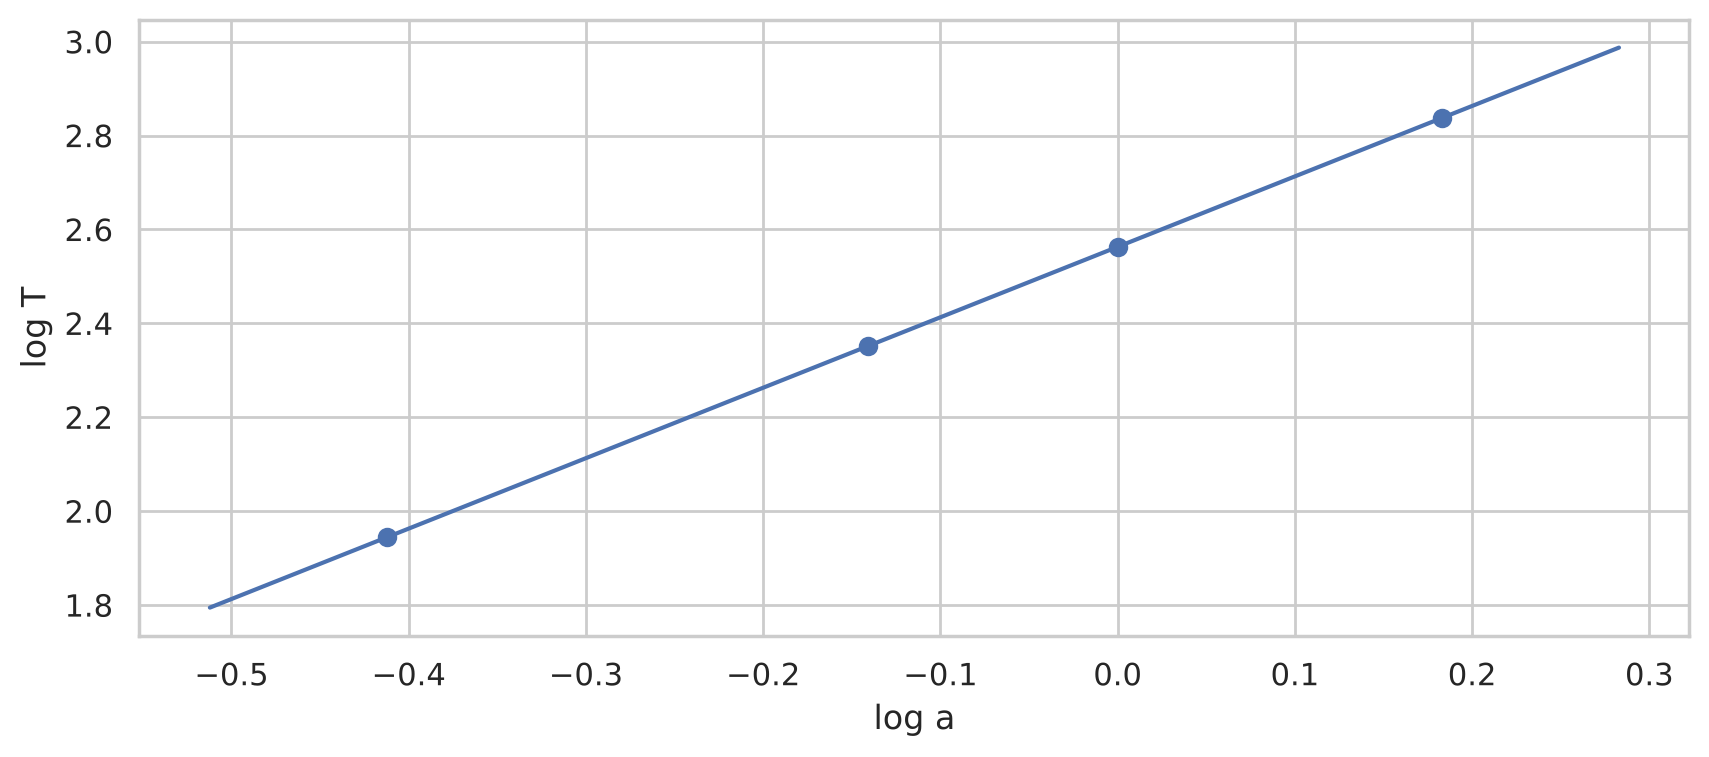

In [22]:
df_ = orbital_params_df.iloc[0:4, :]["T a".split()]
display(df_)
X, y = np.log10(df_[["a"]].values), np.log10(df_["T"].values)
reg = LinearRegression()
reg.fit(X, y)
print(f"Slope: {reg.coef_[0]}")
print(f"Intercept: {reg.intercept_}")

plt.figure(figsize=(10, 4))
plt.scatter(X.flatten(), y)
x_ = np.linspace(X.min()-0.1, X.max()+0.1)
y_ = reg.coef_[0]*x_ + reg.intercept_
plt.plot(x_, y_)
plt.xlabel("log a")
plt.ylabel("log T")
plt.savefig(f"plots/third_law_regression_result_inner_planet.png", dpi=150, bbox_inches='tight');

# Extra

## Orbit Prediction 

using Fourier Regression

### train-test split

In [23]:
training_size = 0.8
train_df = df.iloc[0: int(len(df)*training_size), :]
test_df = df.iloc[int(len(df)*training_size):, ]
print(train_df.shape, test_df.shape)
train_df.head()

(1169, 14) (293, 14)


,day,X,Y,Z,VX,VY,VZ,R,V,theta,cos t,1/r,area,Lz
date,,,,,,,,,,,,,,
2020-01-01,0,-1.320108,-0.885757,0.013829,0.008321,-0.010423,-0.000423,1.589793,0.013344,-2.140548,-0.539423,0.629013,0.01057,0.021129
2020-01-02,1,-1.311738,-0.896147,0.013406,0.008418,-0.010357,-0.000424,1.588684,0.013353,-2.132181,-0.532359,0.629452,0.01057,0.021129
2020-01-03,2,-1.303272,-0.906471,0.012982,0.008514,-0.010291,-0.000425,1.587569,0.013363,-2.123803,-0.525248,0.629894,0.01057,0.021129
2020-01-04,3,-1.294709,-0.916728,0.012557,0.008611,-0.010223,-0.000425,1.586449,0.013373,-2.115413,-0.518091,0.630339,0.01057,0.021129
2020-01-05,4,-1.286051,-0.926917,0.012131,0.008706,-0.010155,-0.000426,1.585323,0.013383,-2.107012,-0.510886,0.630786,0.01057,0.021129


### defining features

In [24]:
T = orbital_params["mars"]["T"]
theta_train = 2*np.pi*train_df["day"].values/T
theta_test = 2*np.pi*test_df["day"].values/T


X_train = pd.DataFrame({"sin theta": np.sin(theta_train), "cos theta": np.cos(theta_train), "sin 2theta": np.sin(2*theta_train), "cos 2theta": np.cos(2*theta_train)})
X_test = pd.DataFrame({"sin theta": np.sin(theta_test), "cos theta": np.cos(theta_test), "sin 2theta": np.sin(2*theta_test), "cos 2theta": np.cos(2*theta_test)})

X_train.head()

,sin theta,cos theta,sin 2theta,cos 2theta
0,0.000000,1.000000,0.000000,1.000000
1,0.009146,0.999958,0.018291,0.999833
2,0.018291,0.999833,0.036575,0.999331
3,0.027434,0.999624,0.054847,0.998495
4,0.036575,0.999331,0.073101,0.997325


### training and prediction

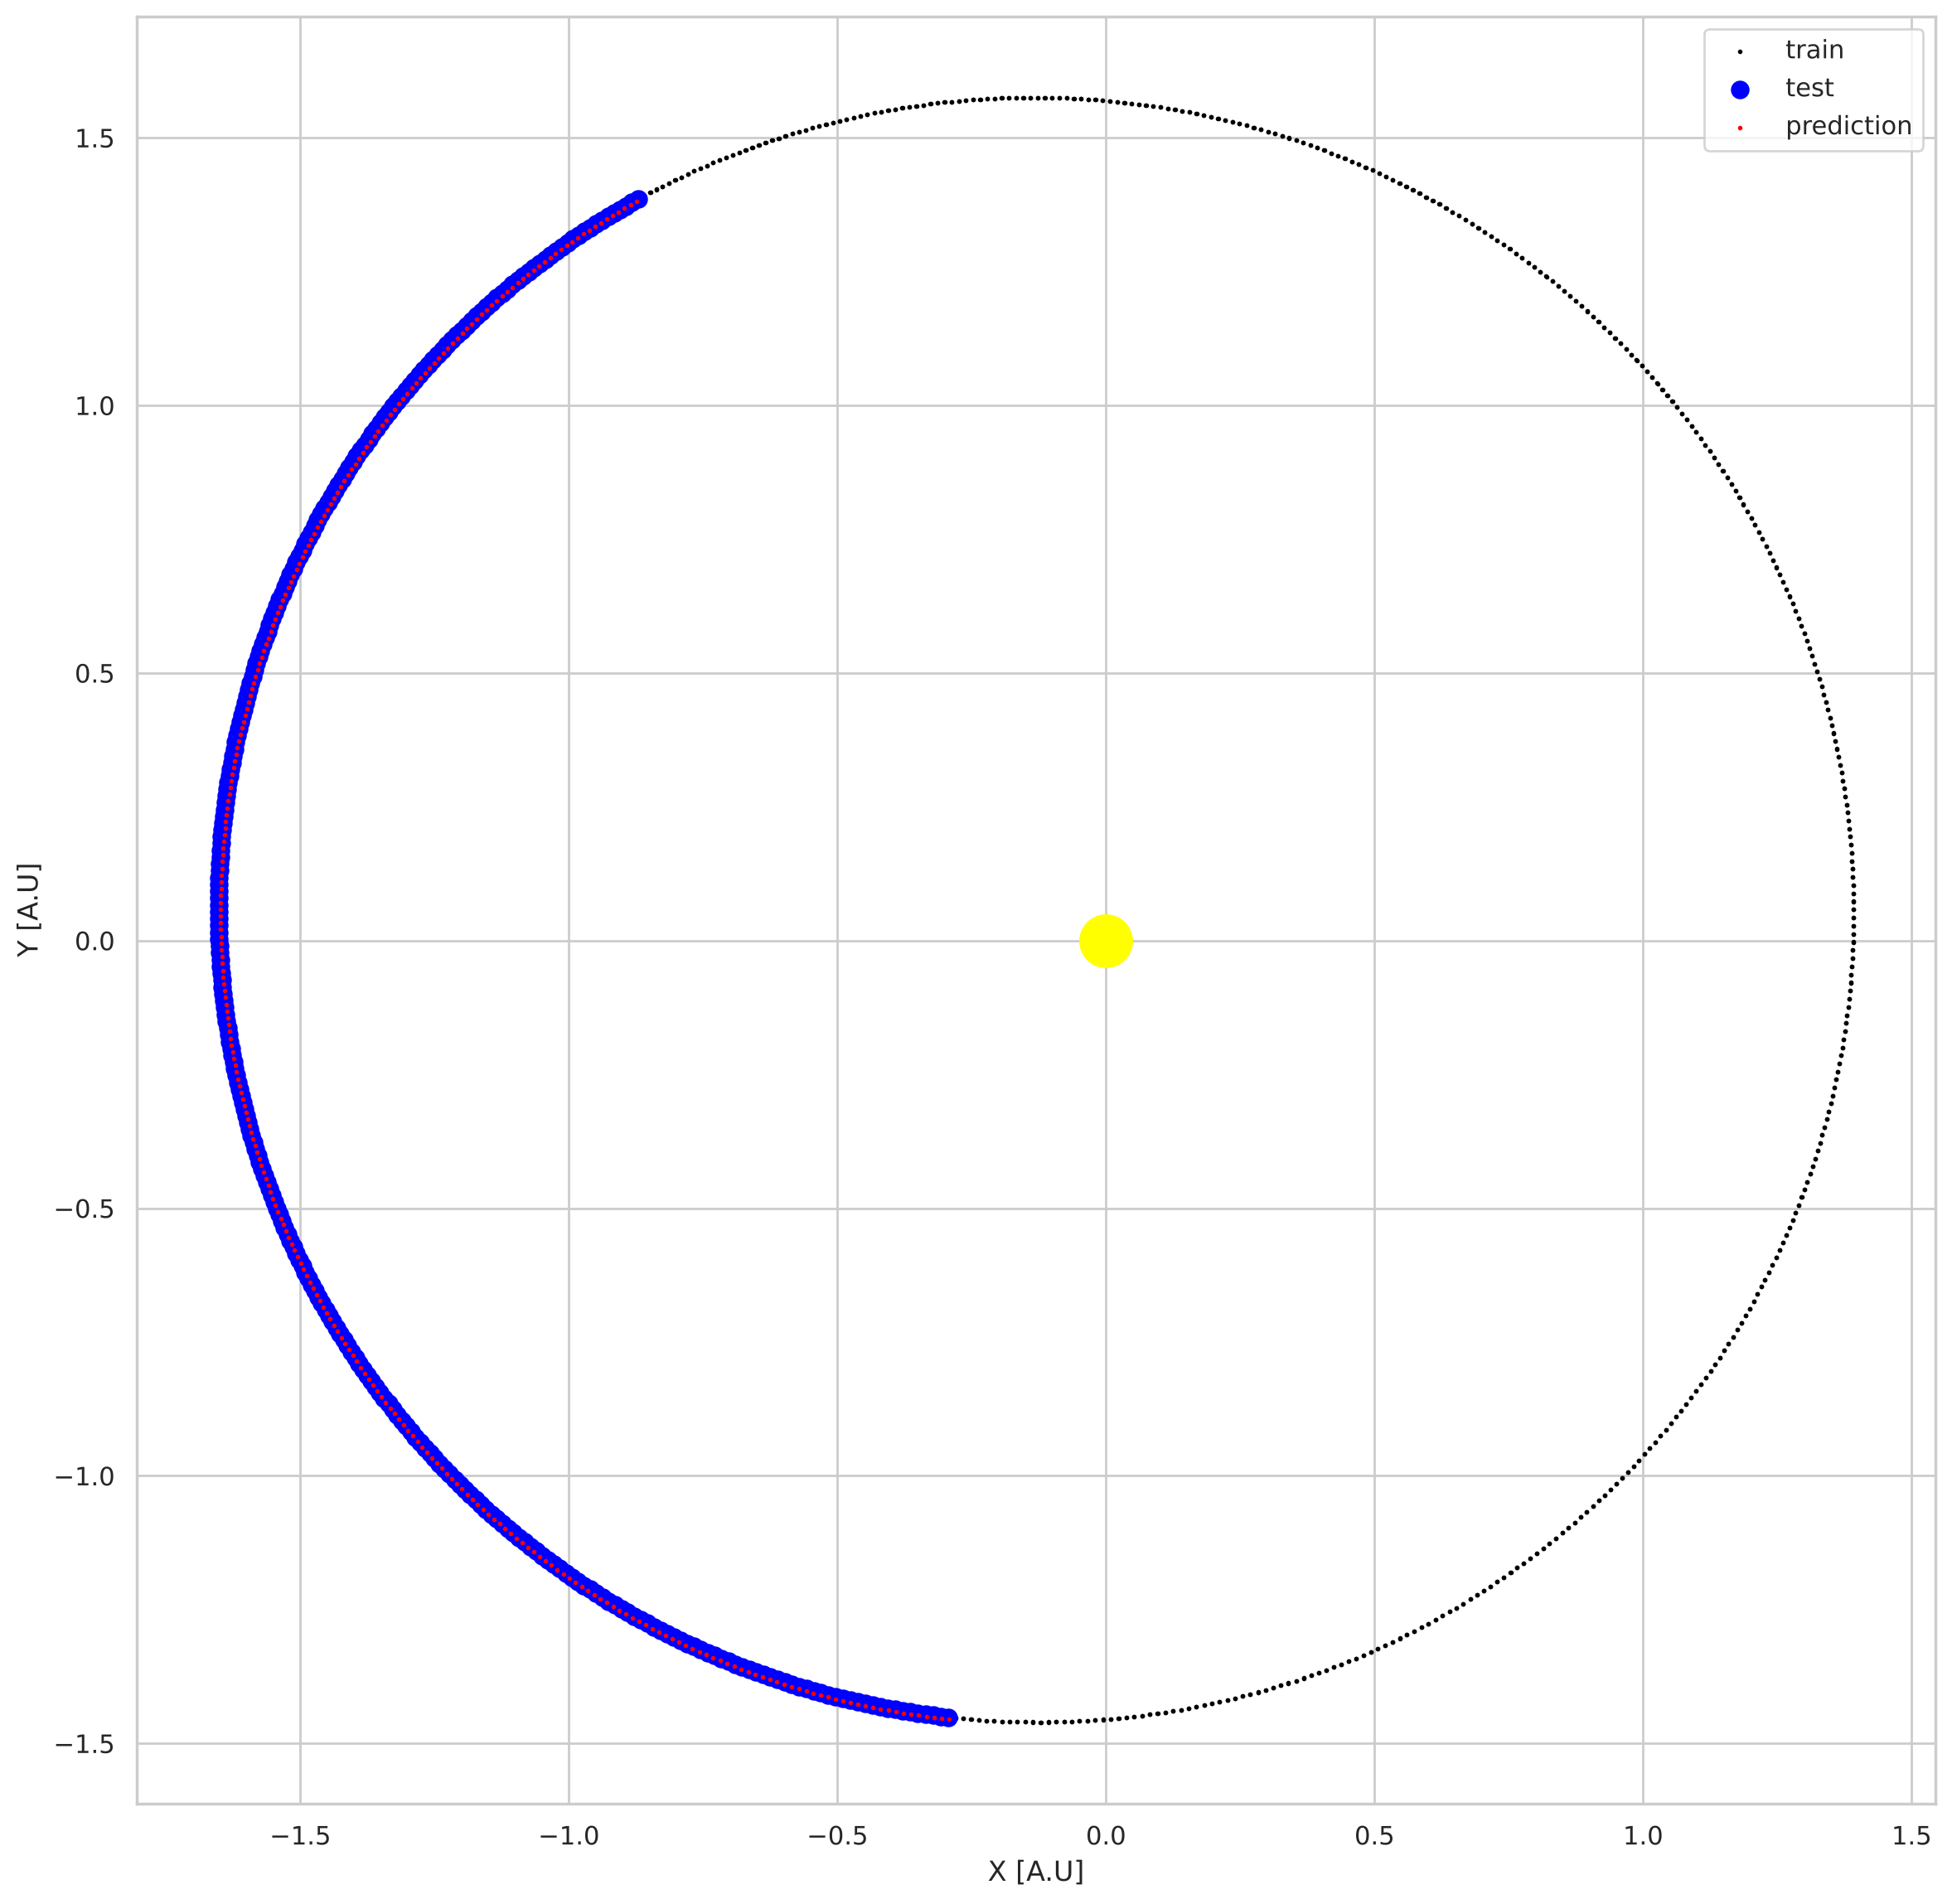

In [25]:
reg_X = do_regression(X_train.values, train_df["X"])
reg_Y = do_regression(X_train.values, train_df["Y"])

pred_df = pd.DataFrame({"day": test_df["day"], "X": reg_X.predict(X_test.values), "Y": reg_Y.predict(X_test.values)})



plt.figure(figsize=(14, 14))
plt.scatter(train_df["X"], train_df["Y"], s=1, color="black", label="train")
plt.scatter(test_df["X"], test_df["Y"], s=50, color="blue", label="test")
plt.scatter(pred_df["X"], pred_df["Y"], s=1, color="red", label="prediction")
plt.scatter(0, 0, s=500, color="yellow")
plt.legend()
plt.xlabel("X [A.U]")
plt.ylabel("Y [A.U]")
plt.axis("equal")
plt.savefig(f"plots/recover_orbit_using_fourier_regression_on_parametric_equation_{planet_}.png", dpi=150, bbox_inches='tight');

In [26]:
rmse = np.sqrt(((pred_df["X"] - test_df["X"])**2 + (pred_df["Y"] - test_df["Y"])**2).mean())
print(f"Position error on the test days (RMSE): {rmse:.4f} AU")

Position error on the test days (RMSE): 0.0057 AU


## Retrograde motion of planets
motion of planets as viewed from Earth

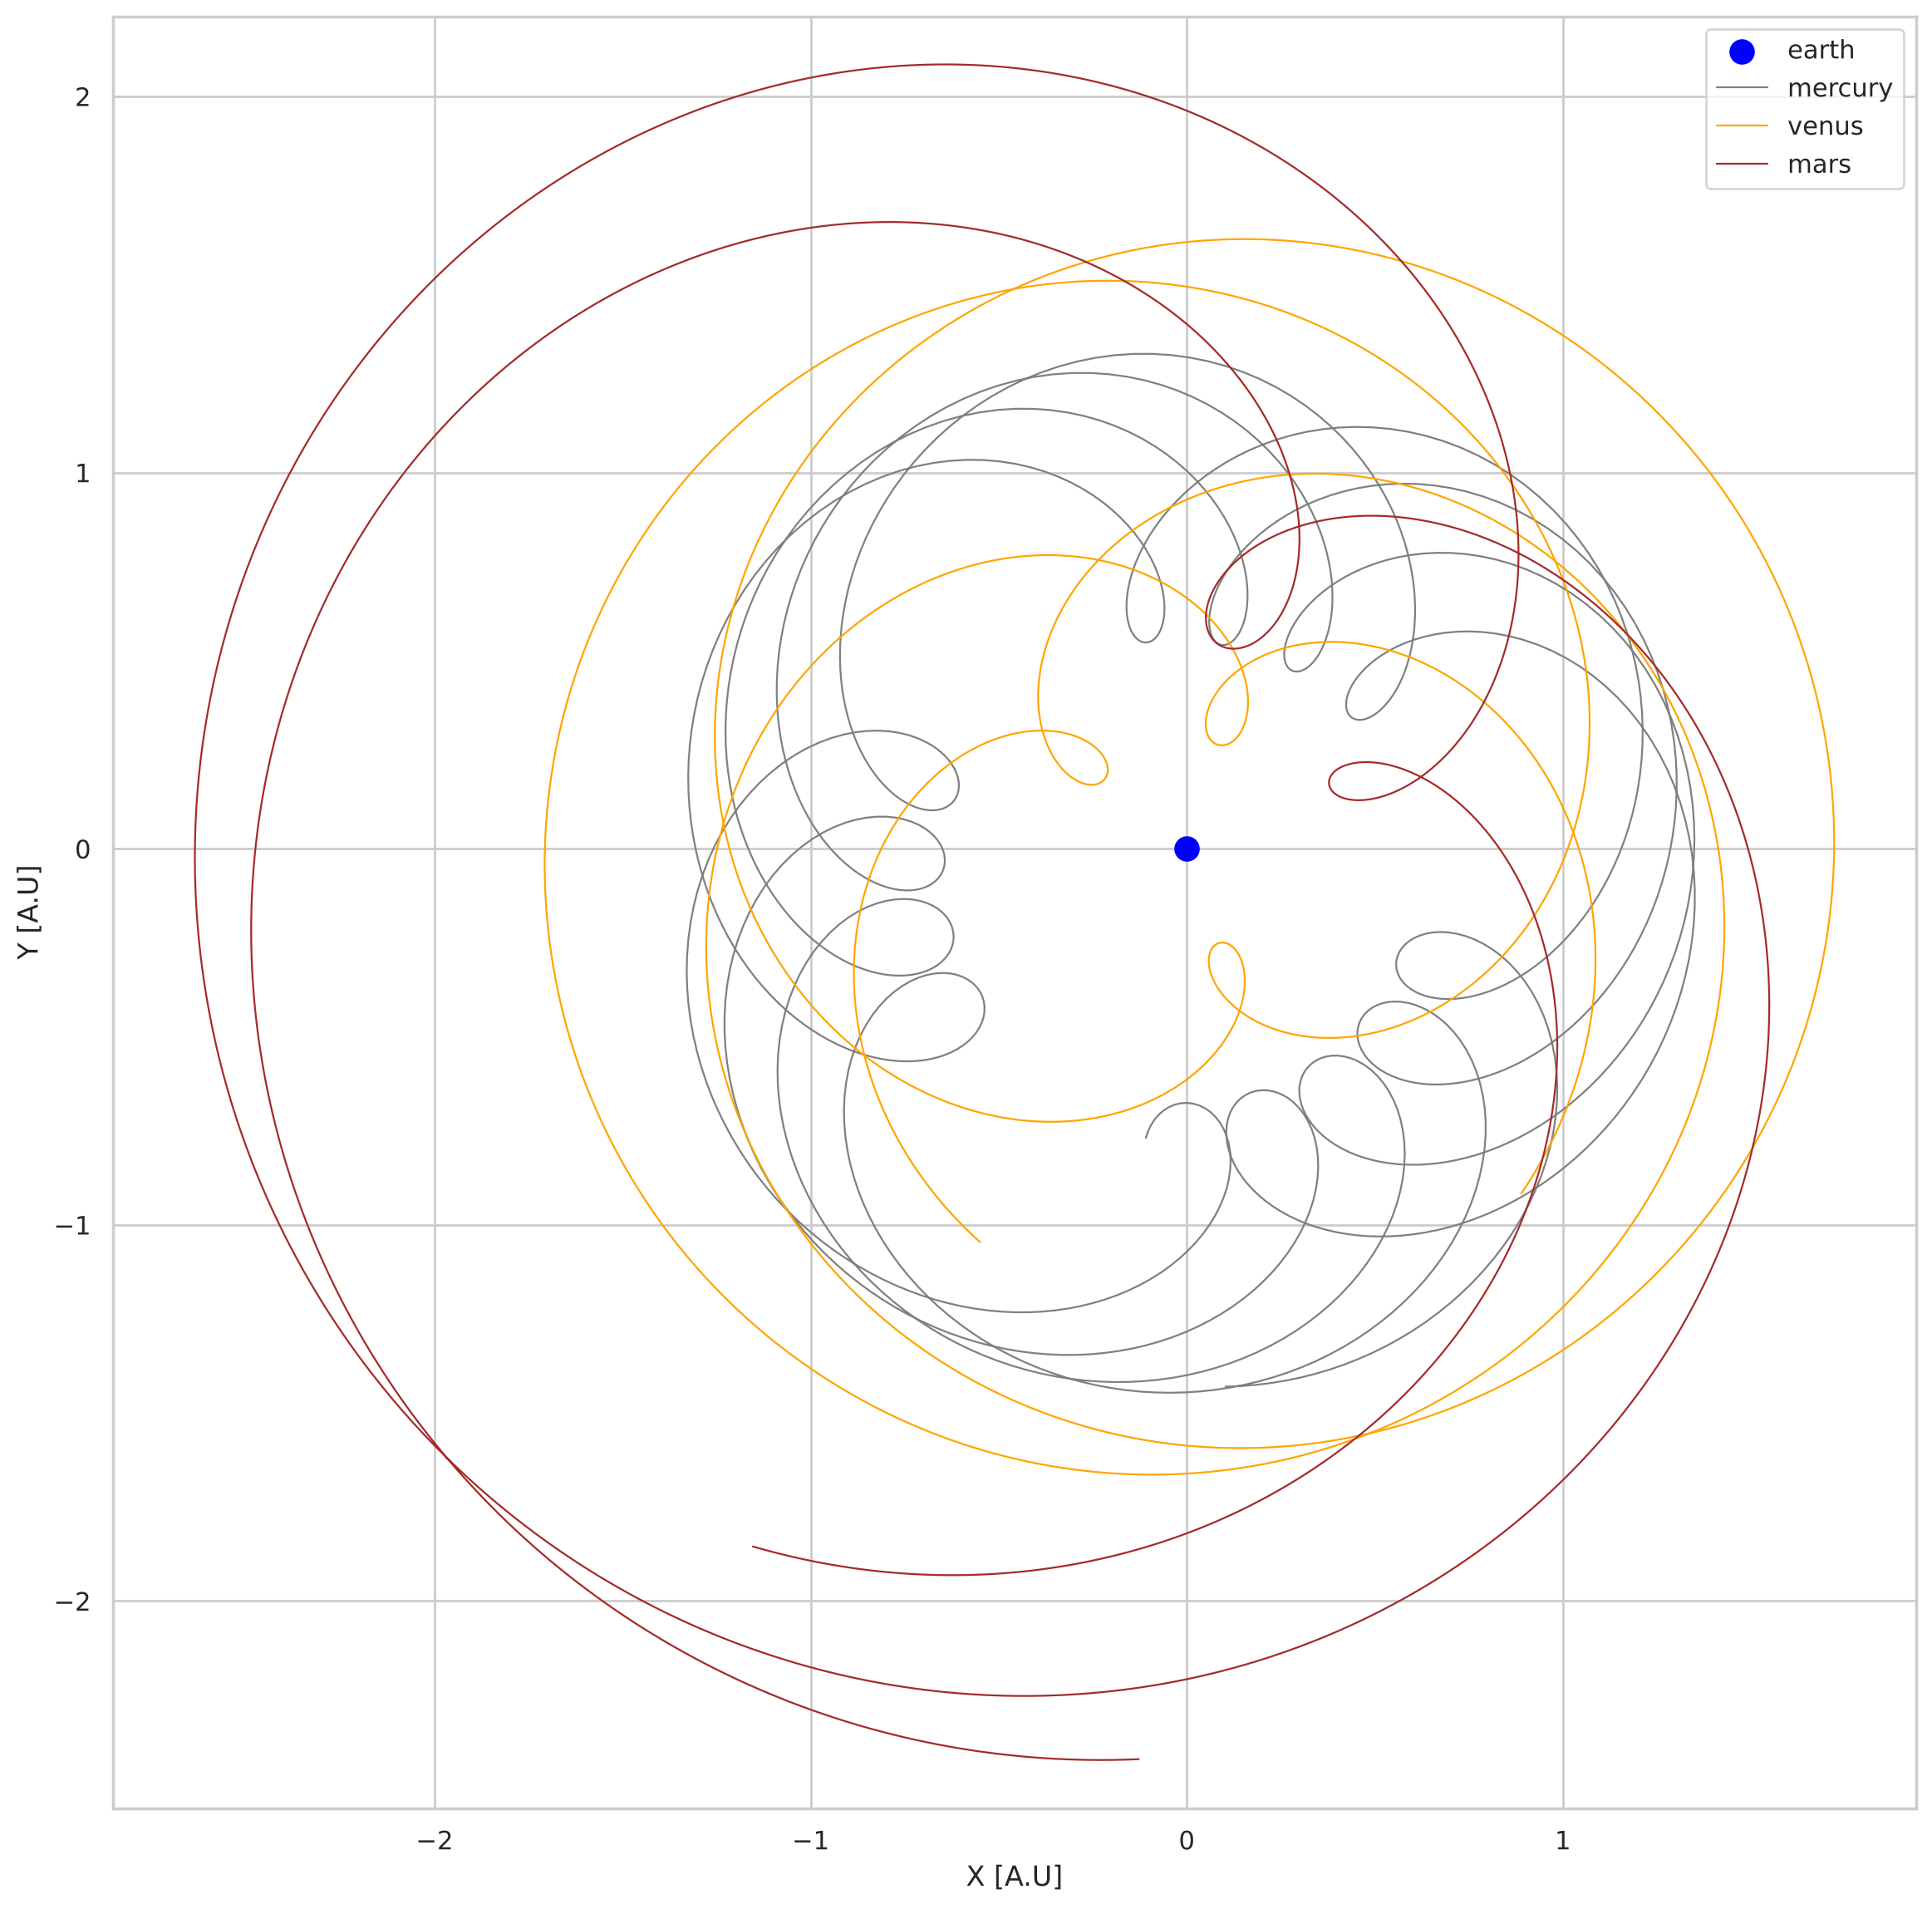

In [27]:
planets = ["mercury", "venus", "mars"]
plt.figure(figsize=(14, 14))
plt.scatter(0, 0, s=100, color="blue", label="earth")
for planet in planets:
    df_ = get_positions_from_earth(planet)
    plt.plot(df_["X"], df_["Y"], color=planet_colors[planet], lw=0.8, label=planet)
plt.legend()
plt.xlabel("X [A.U]")
plt.ylabel("Y [A.U]")
plt.axis("equal")
plt.savefig(f"plots/retrograde_motion_of_planets.png", dpi=150, bbox_inches='tight');

# Summary of results (Mars unless stated)

| Law | Check | Result |
| --- | --- | --- |
| 1. Ellipse | eccentricity from perihelion and aphelion distances vs from regression | 0.0934 and 0.0934 |
| 1. Ellipse | semi-latus rectum, directly vs from regression | 1.5103 AU and 1.5104 AU |
| 2. Equal areas | variation of the area swept per day | about 0.002% |
| 2. Equal areas | area swept in two 27-day windows (days 40-67 and 99-126) | 0.28540 and 0.28541 AU^2 |
| 3. Harmonic law | slope of log T against log a, four inner planets | 1.5003 (expected 1.5) |

**Notes**

- Periods are counted in whole days because the data has one row per day, so Earth shows T = 366 days instead of 365.25. This accounts for the small spread in T^2/a^3 (about 0.5%).
- The data covers only 2020-2024. Planets with periods much longer than four years (Jupiter and beyond) are left out of the period estimate, because there are not enough aphelion passages.
- The Fourier model in the last section is fitted on the first 80% of days and tested on the last 20%. The position error on the test days is 0.0057 AU. It shows that the orbit is periodic. It is not a physical prediction model.